# 00 - Librerias, semilla y  funciones

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import math
import joblib
import os

from sklearn.impute import SimpleImputer
from sklearn.ensemble import IsolationForest
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import RFE, SelectFromModel
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report, accuracy_score, recall_score,f1_score, fbeta_score, precision_score
from sklearn.base import clone

warnings.filterwarnings("ignore")
from sklearn.exceptions import ConvergenceWarning
sns.set_theme(style="darkgrid")
seed = 13

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / 'data').exists() and (PROJECT_ROOT.parent / 'data').exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_DIR = PROJECT_ROOT / 'data'
FIGURES_DIR = PROJECT_ROOT / 'figuras'
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

PLOT_COUNTER = 0

def save_and_show(filename=None, fig=None):
    global PLOT_COUNTER
    if fig is None:
        fig = plt.gcf()

    if filename is None:
        PLOT_COUNTER += 1
        filename = f'plot_{PLOT_COUNTER:03d}.svg'
    else:
        filename = str(filename)
        if not filename.lower().endswith('.svg'):
            filename = f"{Path(filename).stem}.svg"

    output_path = FIGURES_DIR / filename
    fig.savefig(output_path, format='svg', bbox_inches='tight')
    plt.show()

plt.rcParams['savefig.format'] = 'svg'


# 0.1 - Funciones analisis grids

In [2]:
try:
    import seaborn as sns
    _HAS_SEABORN = True
except Exception:
    _HAS_SEABORN = False


# =========================
# Helpers
# =========================
def _pick_first_existing_key(d, keys, default=None):
    for k in keys:
        if k in d:
            return k
    return default


def _ensure_dataframe(X, name="X"):
    if not hasattr(X, "columns"):
        raise TypeError(f"{name} debe ser un pandas DataFrame (tiene que tener .columns).")
    return X


def _extract_cv_df(grid):
    if not hasattr(grid, "cv_results_"):
        raise ValueError("grid debe ser un GridSearchCV ya entrenado (con cv_results_).")
    return pd.DataFrame(grid.cv_results_).copy()


def _split_cols(cv_df):
    return [c for c in cv_df.columns if c.startswith("split") and c.endswith("_test_score")]


def _param_cols(cv_df):
    return [c for c in cv_df.columns if c.startswith("param_")]


def _format_sci(x):
    try:
        return f"{float(x):.0e}"
    except Exception:
        return str(x)


def _slugify_plot_name(name):
    txt = str(name).strip().lower()
    txt = txt.replace(' ', '_').replace('-', '_')
    while '__' in txt:
        txt = txt.replace('__', '_')
    return txt.strip('_')


def _metric_fn(metric):
    """
    Soporta: accuracy, recall, f1, f1_score, f1-score, f2, f2_score, f2-score
    (y en general fbeta:X si quieres: metric="fbeta:2")
    """
    m = metric.lower().strip()

    if m == "accuracy":
        return lambda y_true, y_pred: accuracy_score(y_true, y_pred)

    if m == "recall":
        return lambda y_true, y_pred: recall_score(y_true, y_pred, pos_label=1, zero_division=0)

    if m in ("f1", "f1_score", "f1-score"):
        return lambda y_true, y_pred: f1_score(y_true, y_pred, pos_label=1, zero_division=0)

    if m in ("f2", "f2_score", "f2-score"):
        return lambda y_true, y_pred: fbeta_score(y_true, y_pred, beta=2, pos_label=1, zero_division=0)

    if m.startswith("fbeta:"):
        beta = float(m.split(":", 1)[1])
        return lambda y_true, y_pred: fbeta_score(y_true, y_pred, beta=beta, pos_label=1, zero_division=0)

    raise ValueError("metric debe ser: accuracy | recall | f1_score | f2_score | fbeta:<beta>.")


def _best_threshold_from_probs(y_true, y_prob, metric="f1_score", thresholds=None, tie_break_to_05=True):
    if thresholds is None:
        thresholds = np.linspace(0.0, 1.0, 1001)

    fn = _metric_fn(metric)

    vals = np.empty(len(thresholds), dtype=float)
    for i, t in enumerate(thresholds):
        vals[i] = fn(y_true, (y_prob >= t).astype(int))

    best_val = np.nanmax(vals)
    idxs = np.where(np.isclose(vals, best_val, rtol=1e-12, atol=1e-12))[0]

    if len(idxs) == 1 or not tie_break_to_05:
        best_t = float(thresholds[idxs[0]])
        return best_t, float(best_val), thresholds, vals

    t_candidates = thresholds[idxs]
    best_t = float(t_candidates[np.argmin(np.abs(t_candidates - 0.5))])
    return best_t, float(best_val), thresholds, vals


def _get_feature_names_and_support(best_estimator, preprocess_step_name, selector_step_name):
    pipe = best_estimator
    if not hasattr(pipe, "named_steps"):
        raise ValueError("best_estimator_ no parece ser un Pipeline con named_steps.")

    if preprocess_step_name not in pipe.named_steps:
        raise ValueError(f"No existe el step de preprocesado '{preprocess_step_name}'. Steps: {list(pipe.named_steps)}")
    if selector_step_name not in pipe.named_steps:
        raise ValueError(f"No existe el step del selector '{selector_step_name}'. Steps: {list(pipe.named_steps)}")

    preprocess = pipe.named_steps[preprocess_step_name]
    selector = pipe.named_steps[selector_step_name]

    if not hasattr(preprocess, "get_feature_names_out"):
        raise ValueError(f"El step '{preprocess_step_name}' no implementa get_feature_names_out().")

    feat_names = preprocess.get_feature_names_out()

    if hasattr(selector, "get_support"):
        support = selector.get_support()
    elif hasattr(selector, "support_"):
        support = selector.support_
    else:
        raise ValueError(f"El selector '{selector_step_name}' no tiene get_support()/support_.")

    feat_names = np.array(feat_names, dtype=object)
    support = np.array(support, dtype=bool)

    if feat_names.shape[0] != support.shape[0]:
        raise ValueError("feature_names y support_ no tienen la misma longitud. Revisa ColumnTransformer/selector.")

    return feat_names, support


def _feature_base_name(feat_name, original_cols):
    name = str(feat_name)
    if "__" in name:
        name = name.split("__", 1)[1]

    if not original_cols:
        return name

    if name in original_cols:
        return name

    for c in original_cols:
        if name.startswith(f"{c}_"):
            return c

    matches = [c for c in original_cols if c in name]
    if matches:
        return sorted(matches, key=len, reverse=True)[0]

    return name


def _plot_selected_count(feat_names, support, top_k=None, title="Variables seleccionadas", original_cols=None, filename=None):
    selected = feat_names[support]
    if selected.size == 0:
        print("[WARN] No hay features seleccionadas por el selector.")
        return

    original_cols = list(original_cols) if original_cols is not None else []
    selected_display = [_feature_base_name(f, original_cols) for f in selected]

    s = pd.Series(selected_display).value_counts()
    if top_k is not None:
        s = s.head(int(top_k))

    plt.figure(figsize=(12, max(4, 0.35 * len(s))))
    if _HAS_SEABORN:
        sns.barplot(x=s.values, y=s.index)
        plt.xlabel("count")
        plt.ylabel("variable")
    else:
        plt.barh(s.index, s.values)
        plt.xlabel("count")
        plt.ylabel("variable")
    plt.title(title)
    plt.tight_layout()
    save_and_show(filename)


def _topN_selected_features_details(
    grid,
    X_train,
    y_train,
    topN=10,
    preprocess_step_candidates=("preprocess", "col_trasnf", "col_transf"),
    selector_step_candidates=("selector", "var_selection", "rfe"),
    original_cols=None,
    verbose=True,
):
    cv_df = _extract_cv_df(grid)
    top = (cv_df
           .sort_values(["mean_test_score", "std_test_score"], ascending=[False, True])
           .head(int(topN))
           .reset_index(drop=True))

    if top.empty:
        return pd.DataFrame(columns=["variable", "count"]) 

    if "params" not in top.columns:
        if verbose:
            print("[WARN] cv_results_ no tiene columna 'params'.")
        return pd.DataFrame(columns=["variable", "count"]) 

    original_cols = list(original_cols) if original_cols is not None else []
    selected_all = []

    for i in range(len(top)):
        params = top.loc[i, "params"]
        if not isinstance(params, dict):
            continue

        est = clone(grid.estimator)
        est.set_params(**params)
        est.fit(X_train, y_train)

        preprocess_step_name = _pick_first_existing_key(est.named_steps, preprocess_step_candidates, default=None)
        selector_step_name = _pick_first_existing_key(est.named_steps, selector_step_candidates, default=None)

        if preprocess_step_name is None or selector_step_name is None:
            continue

        feat_names, support = _get_feature_names_and_support(
            best_estimator=est,
            preprocess_step_name=preprocess_step_name,
            selector_step_name=selector_step_name,
        )

        selected = feat_names[support]
        selected_display = [_feature_base_name(f, original_cols) for f in selected]
        selected_all.extend(selected_display)

    if len(selected_all) == 0:
        return pd.DataFrame(columns=["variable", "count"])

    details = (pd.Series(selected_all)
               .value_counts()
               .rename_axis("variable")
               .reset_index(name="count")
               .sort_values(["count", "variable"], ascending=[False, True])
               .reset_index(drop=True))
    return details


def _plot_topN_selected_features_count(details_df, top_k=None, title="Variables seleccionadas en el TOP-N", filename=None):
    if details_df is None or details_df.empty:
        print("[WARN] No hay variables seleccionadas en el TOP-N para graficar.")
        return

    d = details_df.copy()
    d = d[d["count"] >= 1]
    if top_k is not None:
        d = d.head(int(top_k))

    plt.figure(figsize=(12, max(4, 0.35 * len(d))))
    if _HAS_SEABORN:
        sns.barplot(data=d, x="count", y="variable")
    else:
        plt.barh(d["variable"], d["count"])
    plt.xlabel("count")
    plt.ylabel("variable")
    plt.title(title)
    plt.tight_layout()
    save_and_show(filename)


def _clean_param_name(pc):
    name = pc.replace("param_", "")
    if "__" in name:
        name = name.split("__", 1)[1]
    return name


def _top_models_boxplot(cv_df, topN=10, tag="", max_label_len=180, filename=None):
    splits = _split_cols(cv_df)
    if not splits:
        print(f"[WARN] No hay split*_test_score para boxplot TOP en {tag}")
        return

    top = (cv_df
           .sort_values(["mean_test_score", "std_test_score"], ascending=[False, True])
           .head(int(topN))
           .reset_index(drop=True))

    pcols = _param_cols(top)
    clean_map = {pc: _clean_param_name(pc) for pc in pcols}

    labels, data = [], []
    for i in range(len(top)):
        row = top.loc[i]
        parts = []
        for pc, cn in clean_map.items():
            v = row[pc]
            if pd.isna(v):
                continue
            if any(s in cn.lower() for s in ["alpha", "lr", "learning_rate"]):
                v = _format_sci(v)
            else:
                v = str(v)
            parts.append(f"{v}")

        lab = ", ".join(parts) if parts else f"cfg_{i}"
        if len(lab) > max_label_len:
            lab = lab[:max_label_len - 3] + "..."
        labels.append(lab)

        scores = top.loc[i, splits].astype(float).to_numpy()
        data.append(scores)

    plt.figure(figsize=(max(14, 1.2 * min(topN, len(top))), 6))
    plt.boxplot(data, labels=labels, showmeans=True)
    plt.ylabel("CV split test score")
    plt.title(f"Top {min(topN, len(top))} configs por mean_test_score {('- ' + tag) if tag else ''}")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    save_and_show(filename)


def _boxplots_by_hyperparam(cv_df, ncols=3, figsize_per_plot=(6, 4), tag="", filename=None):
    splits = _split_cols(cv_df)
    pcols = _param_cols(cv_df)
    if not splits or not pcols:
        print(f"[WARN] No hay split cols o param cols para boxplots por hiperparámetro en {tag}")
        return

    n = len(pcols)
    nrows = int(np.ceil(n / ncols))
    fig, axes = plt.subplots(
        nrows=nrows, ncols=ncols,
        figsize=(figsize_per_plot[0] * ncols, figsize_per_plot[1] * nrows),
        squeeze=False
    )
    axes = axes.flatten()

    for i, pc in enumerate(pcols):
        ax = axes[i]
        dfp = cv_df[[pc] + splits].copy()
        dfp = dfp.dropna(subset=[pc])
        dfp[pc] = dfp[pc].astype(str)

        long = dfp.melt(
            id_vars=[pc],
            value_vars=splits,
            var_name="split",
            value_name="score"
        ).dropna(subset=["score"])

        med = long.groupby(pc)["score"].median().sort_values(ascending=False)
        cats = med.index.tolist()
        data = [long.loc[long[pc] == c, "score"].astype(float).to_numpy() for c in cats]

        ax.boxplot(data, labels=cats)
        ax.set_title(f"CV por: {pc.replace('param_', '')}")
        ax.set_ylabel("CV split test score")
        ax.tick_params(axis="x", rotation=0)

    for j in range(i + 1, len(axes)):
        fig.delaxes(axes[j])

    plt.suptitle(f"Boxplots CV por hiperparámetro {('- ' + tag) if tag else ''}", y=1.02)
    plt.tight_layout()
    save_and_show(filename)


# =========================
# Main reusable function
# =========================
def evaluate_grid_threshold_and_plots(
    grid,
    X_train, y_train,
    X_test,  y_test,
    threshold_on="train",
    threshold_metric="f1_score",
    fixed_threshold=None, # <--- NUEVO PARAMETRO
    thresholds=None,
    preprocess_step_candidates=("preprocess", "col_trasnf", "col_transf"),
    selector_step_candidates=("selector", "var_selection", "rfe"),
    topN=10,
    plot_confusion=True,
    plot_selected_count=True,
    selected_count_top_k=None,
    plot_top_models=True,
    plot_param_boxplots=True,
    plot_topN_selection=False,
    topN_selection_top_k=None,
    verbose=True,
    model_tag="modelo",
):
    _ensure_dataframe(X_train, "X_train")
    _ensure_dataframe(X_test, "X_test")

    if not hasattr(grid, "best_estimator_"):
        raise ValueError("grid debe estar entrenado (falta best_estimator_).")

    best_pipe = grid.best_estimator_
    if not hasattr(best_pipe, "named_steps"):
        raise ValueError("best_estimator_ no es un Pipeline con named_steps.")

    if thresholds is None:
        thresholds = np.linspace(0.0, 1.0, 1001)

    if threshold_on not in ("train", "test"):
        raise ValueError("threshold_on debe ser 'train' o 'test'.")

    if not hasattr(best_pipe, "predict_proba"):
        raise ValueError("El best_estimator_ no tiene predict_proba(). No puedo optimizar threshold.")

    model_tag = _slugify_plot_name(model_tag) if model_tag else "modelo"

    # 1. Obtener probabilidades en el conjunto de decisión (train o test)
    X_thr = X_train if threshold_on == "train" else X_test
    y_thr = y_train if threshold_on == "train" else y_test
    y_prob_thr = best_pipe.predict_proba(X_thr)[:, 1]

    # 2. Decidir el threshold (fijo o optimizado)
    if fixed_threshold is not None:
        # Si el usuario define un threshold, usamos ese.
        best_t = float(fixed_threshold)
        
        # Calculamos el score de la métrica solo para mostrarlo en el reporte
        fn_metric = _metric_fn(threshold_metric)
        best_m = fn_metric(y_thr, (y_prob_thr >= best_t).astype(int))
        
        if verbose:
            print("=" * 90)
            print("Steps del pipeline:", list(best_pipe.named_steps.keys()))
            print("Best params:", getattr(grid, "best_params_", None))
            print("Best CV score:", getattr(grid, "best_score_", None))
            print(f"[INFO] Threshold FIJO definido por usuario: {best_t:.4f}")
            print(f"       Métrica resultante ({threshold_metric}) en {threshold_on.upper()}: {best_m:.6f}")

    else:
        # Si NO se define, hacemos la optimización estándar
        best_t, best_m, _, _ = _best_threshold_from_probs(
            y_true=y_thr,
            y_prob=y_prob_thr,
            metric=threshold_metric,
            thresholds=thresholds,
        )
        if verbose:
            print("=" * 90)
            print("Steps del pipeline:", list(best_pipe.named_steps.keys()))
            print("Best params:", getattr(grid, "best_params_", None))
            print("Best CV score:", getattr(grid, "best_score_", None))
            print(f"Best threshold ({threshold_metric}) optimizado en {threshold_on.upper()}: {best_t:.4f} (score={best_m:.6f})")

    # 3. Aplicar al test final
    y_prob_test = best_pipe.predict_proba(X_test)[:, 1]
    y_pred_test = (y_prob_test >= best_t).astype(int)

    if verbose:
        print("Classification report (TEST):")
        print(classification_report(y_test, y_pred_test, digits=4, zero_division=0))

    cm = confusion_matrix(y_test, y_pred_test, labels=[0, 1])

    if plot_confusion:
        ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=[0, 1]).plot(values_format="d")
        plt.title(f"Matriz de confusión (thr={best_t:.3f})")
        plt.tight_layout()
        save_and_show(f'matriz_confusion_{model_tag}.svg')

    preprocess_step_name = _pick_first_existing_key(best_pipe.named_steps, preprocess_step_candidates, default=None)
    selector_step_name = _pick_first_existing_key(best_pipe.named_steps, selector_step_candidates, default=None)

    selected_features = None
    ranking_df = None

    if preprocess_step_name is not None and selector_step_name is not None:
        feat_names, support = _get_feature_names_and_support(
            best_estimator=best_pipe,
            preprocess_step_name=preprocess_step_name,
            selector_step_name=selector_step_name,
        )
        selected_features = feat_names[support].tolist()

        selector_obj = best_pipe.named_steps[selector_step_name]
        ranking = getattr(selector_obj, "ranking_", None)
        if ranking is not None:
            ranking_df = (pd.DataFrame({
                "feature": feat_names,
                "selected": support,
                "ranking": ranking,
            }).sort_values(["selected", "ranking"], ascending=[False, True]))

        if verbose:
            print("Features seleccionadas por el selector:")
            print(selected_features)

        if plot_selected_count:
            _plot_selected_count(
                feat_names=feat_names,
                support=support,
                top_k=selected_count_top_k,
                title="Countplot - variables seleccionadas (mejor modelo)",
                original_cols=list(X_train.columns),
                filename=f'countplot_variables_seleccionadas_{model_tag}.svg',
            )
    else:
        if verbose:
            print("[WARN] No pude localizar steps preprocess/selector para extraer features seleccionadas.")

    cv_df = _extract_cv_df(grid)

    if plot_top_models:
        _top_models_boxplot(
            cv_df,
            topN=topN,
            tag="grid",
            filename=f'boxplot_modelos_general_{model_tag}.svg',
        )

    if plot_param_boxplots:
        _boxplots_by_hyperparam(
            cv_df,
            ncols=3,
            figsize_per_plot=(6, 4),
            tag="grid",
            filename=f'boxplot_hiperparametros_{model_tag}.svg',
        )

    topN_selection_details = _topN_selected_features_details(
        grid=grid,
        X_train=X_train,
        y_train=y_train,
        topN=topN,
        preprocess_step_candidates=preprocess_step_candidates,
        selector_step_candidates=selector_step_candidates,
        original_cols=list(X_train.columns),
        verbose=verbose,
    )

    if plot_topN_selection:
        _plot_topN_selected_features_count(
            details_df=topN_selection_details,
            top_k=topN_selection_top_k,
            title="Variables seleccionadas en configuraciones TOP-N",
            filename=f'countplot_topn_variables_{model_tag}.svg',
        )

    return {
        "best_params": getattr(grid, "best_params_", None),
        "best_cv_score": float(getattr(grid, "best_score_", np.nan)) if getattr(grid, "best_score_", None) is not None else np.nan,
        "threshold_metric": threshold_metric,
        "threshold_on": threshold_on,
        "best_threshold": float(best_t),
        "best_threshold_metric_value": float(best_m),
        "confusion_matrix": cm,
        "selected_features": selected_features,
        "ranking_df": ranking_df,
        "cv_results_df": cv_df,
        "topN_selection_details": topN_selection_details,
    }

# 01 - Carga de datos y renombrado

In [3]:
rename_dict = {
    'V1': 'state', 'V2': 'account_length', 'V3': 'area_code',
    'V4': 'phone_number', 'V5': 'international_plan', 'V6': 'voice_mail_plan',
    'V7': 'number_vmail_messages', 'V8': 'total_day_minutes', 'V9': 'total_day_calls',
    'V10': 'total_day_charge', 'V11': 'total_evening_minutes', 'V12': 'total_evening_calls',
    'V13': 'total_evening_charge', 'V14': 'total_night_minutes', 'V15': 'total_night_calls',
    'V16': 'total_night_charge', 'V17': 'total_international_minutes', 'V18': 'total_international_calls',
    'V19': 'total_international_charge', 'V20': 'customer_service_calls', 'Y': 'y'
}

df_raw = pd.read_csv(DATA_DIR / 'BBDD_ML_TAREA.csv').rename(columns=rename_dict)
df_raw.head()

,state,account_length,area_code,phone_number,international_plan,voice_mail_plan,number_vmail_messages,total_day_minutes,total_day_calls,total_day_charge,...,total_evening_calls,total_evening_charge,total_night_minutes,total_night_calls,total_night_charge,total_international_minutes,total_international_calls,total_international_charge,customer_service_calls,y
0,43,121,415.0,1118,0,0,0,86.1,100,14.64,...,113,22.08,148.0,79.0,6.66,9.1,9,2.46,2,0
1,7,170,510.0,3326,0,0,0,184.1,106,31.30,...,70,17.42,224.3,133.0,10.09,9.8,3,2.65,2,0
2,31,96,510.0,2146,0,0,0,150.0,122,25.50,...,116,18.57,212.4,89.0,9.56,9.8,1,2.65,3,0
3,17,90,415.0,387,0,0,0,193.7,83,32.93,...,79,13.11,299.0,60.0,13.46,12.7,3,3.43,1,0
4,7,61,415.0,313,0,0,0,140.6,89,23.90,...,128,14.69,212.4,97.0,9.56,13.6,4,3.67,1,0


# 02 - Revision de duplicados (sin perder el dataset con duplicados)

In [4]:
df_dup = df_raw.copy()
df_nodup = df_raw.drop_duplicates().reset_index(drop=True)

print(f'Duplicados: {df_dup.duplicated().sum()}')
print('Dimensión con duplicados:', df_dup.shape)
print('Dimensión sin duplicados:', df_nodup.shape)

print('\nDistribucion de y con duplicados:')
print(df_dup['y'].value_counts())
print('\nDistribucion de y sin duplicados (desbalanceado):')
print(df_nodup['y'].value_counts())

Duplicados: 5662
Dimensión con duplicados: (9200, 21)
Dimensión sin duplicados: (3538, 21)

Distribucion de y con duplicados:
y
0    4600
1    4600
Name: count, dtype: int64

Distribucion de y sin duplicados (desbalanceado):
y
0    2832
1     706
Name: count, dtype: int64


In [5]:
df_nodup.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3538 entries, 0 to 3537
Data columns (total 21 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   state                        3538 non-null   int64  
 1   account_length               3538 non-null   int64  
 2   area_code                    3503 non-null   float64
 3   phone_number                 3538 non-null   int64  
 4   international_plan           3538 non-null   int64  
 5   voice_mail_plan              3538 non-null   int64  
 6   number_vmail_messages        3538 non-null   int64  
 7   total_day_minutes            3538 non-null   float64
 8   total_day_calls              3538 non-null   int64  
 9   total_day_charge             3525 non-null   float64
 10  total_evening_minutes        3538 non-null   float64
 11  total_evening_calls          3538 non-null   int64  
 12  total_evening_charge         3538 non-null   float64
 13  total_night_minute

In [6]:
df_nodup.describe()

,state,account_length,area_code,phone_number,international_plan,voice_mail_plan,number_vmail_messages,total_day_minutes,total_day_calls,total_day_charge,...,total_evening_calls,total_evening_charge,total_night_minutes,total_night_calls,total_night_charge,total_international_minutes,total_international_calls,total_international_charge,customer_service_calls,y
count,3538.000000,3538.000000,3503.000000,3538.000000,3538.000000,3538.000000,3538.000000,3538.000000,3538.000000,3525.000000,...,3538.000000,3538.000000,3512.000000,3510.000000,3538.000000,3538.000000,3538.000000,3522.000000,3538.000000,3538.000000
mean,25.976540,100.676371,436.903797,2491.100904,0.109101,0.258338,7.587337,181.799406,100.226964,30.928159,...,100.578010,17.065772,200.781891,99.674644,9.038867,10.264189,4.442623,2.771303,1.599209,0.199548
std,14.775151,39.697080,42.184498,1445.915241,0.311810,0.437783,13.453777,55.500550,19.777893,9.431356,...,19.615148,4.337158,50.594675,20.079583,2.275700,2.746504,2.506359,0.742264,1.355173,0.399717
min,0.000000,1.000000,408.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,12.000000,1.900000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,13.250000,73.000000,415.000000,1225.250000,0.000000,0.000000,0.000000,144.425000,88.000000,24.570000,...,88.000000,14.100000,167.300000,86.000000,7.532500,8.500000,3.000000,2.300000,1.000000,0.000000
50%,26.000000,100.000000,415.000000,2504.500000,0.000000,0.000000,0.000000,181.100000,100.000000,30.820000,...,100.000000,17.170000,200.450000,100.000000,9.040000,10.300000,4.000000,2.780000,1.000000,0.000000
75%,39.000000,126.000000,415.000000,3743.750000,0.000000,1.000000,15.000000,218.675000,114.000000,37.210000,...,114.000000,20.000000,235.300000,113.000000,10.590000,12.000000,6.000000,3.240000,2.000000,0.000000
max,50.000000,243.000000,510.000000,4999.000000,1.000000,1.000000,52.000000,351.500000,160.000000,59.760000,...,170.000000,30.910000,395.000000,175.000000,17.770000,20.000000,20.000000,5.400000,9.000000,1.000000


# 04 - Búsqueda de valores extremos mediante: IQR + IsolationForest

In [7]:
cat_cols = ['state', 'area_code', 'international_plan', 'voice_mail_plan']
num_discretas_cols = ['customer_service_calls', 'total_international_calls', 'number_vmail_messages']
target = 'y'

col_sin_target = [col for col in df_nodup.columns if col != target]
num_cols = [
    col for col in df_nodup.select_dtypes(include=np.number).columns
    if col not in num_discretas_cols + [target] + cat_cols + ['phone_number']
]

data = df_nodup.copy()
X_num = data[num_cols].copy()

In [8]:
X_num.columns

Index(['account_length', 'total_day_minutes', 'total_day_calls',
       'total_day_charge', 'total_evening_minutes', 'total_evening_calls',
       'total_evening_charge', 'total_night_minutes', 'total_night_calls',
       'total_night_charge', 'total_international_minutes',
       'total_international_charge'],
      dtype='object')

## 04.01 - Rango Intercuartílico

In [9]:
# IQR
Q1 = X_num.quantile(0.25)
Q3 = X_num.quantile(0.75)
IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR
# Si un registro es outlier en al menos una de las columnas continuas, se marca como True
iqr_outlier_mask = ((X_num < lower) | (X_num > upper)).any(axis=1)

## 04.02 - Isolation Forest

In [10]:
# Método Isolation Forest

contamination = 0.05

imputer = SimpleImputer(strategy='median')
X_imp = imputer.fit_transform(X_num)

iso = IsolationForest(n_estimators=300, contamination=contamination, random_state=42)
iso_labels = iso.fit_predict(X_imp)
sk_outlier_mask = iso_labels == -1

## 04.03 - Resumen de Outliers

In [11]:
# Guardar resultados en el DataFrame original
data['outlier_iqr'] = iqr_outlier_mask
data['outlier_sklearn'] = sk_outlier_mask
data['outlier_ambos'] = data['outlier_iqr'] & data['outlier_sklearn']
data['outlier_cualquiera'] = data['outlier_iqr'] | data['outlier_sklearn']

print(f'Filas totales: {len(data)}')
print(f"Outliers por IQR: {data['outlier_iqr'].sum()}")
print(f"Outliers por sklearn: {data['outlier_sklearn'].sum()}")
print(f"Outliers detectados por ambos: {data['outlier_ambos'].sum()}")


Filas totales: 3538
Outliers por IQR: 227
Outliers por sklearn: 177
Outliers detectados por ambos: 83


## 04.04 - Resumen visual de Outliers

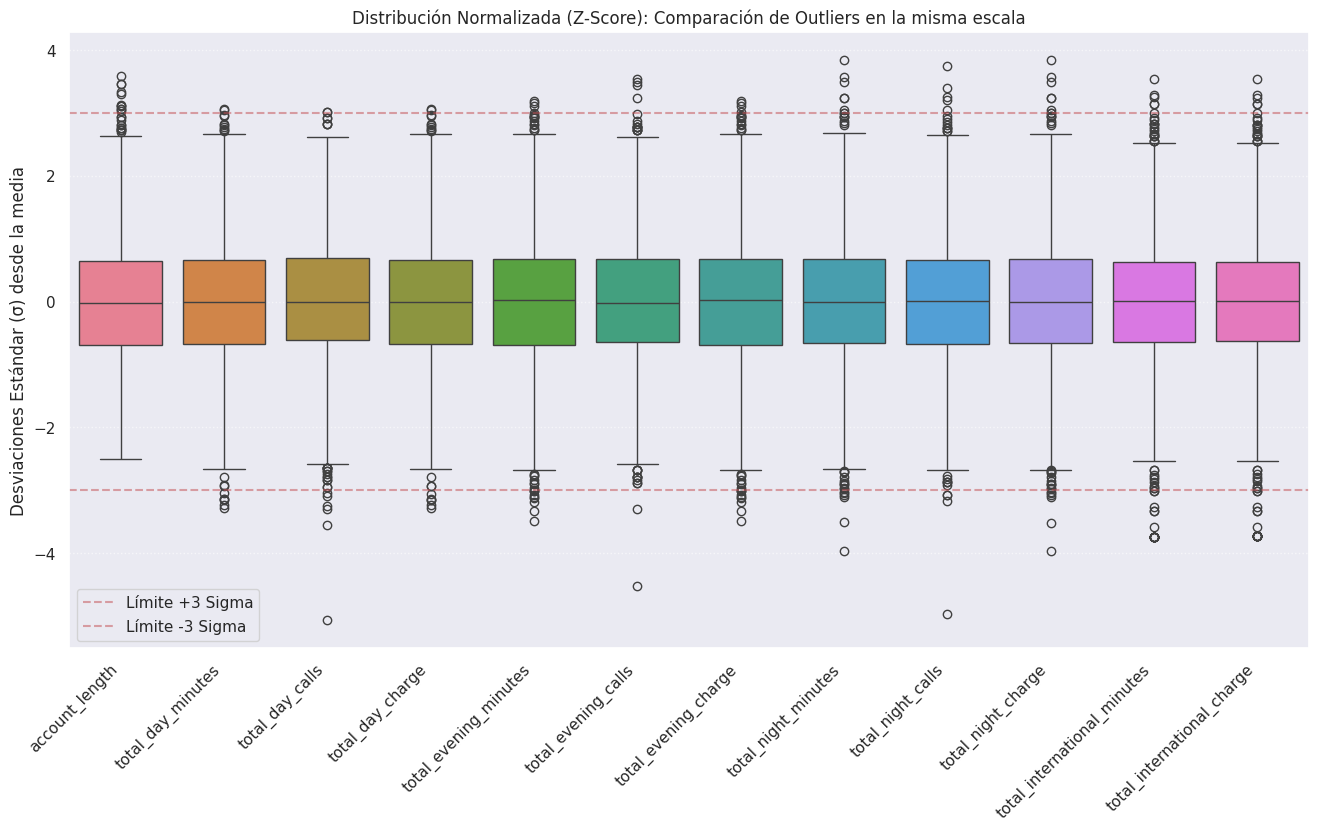

In [12]:
# 1. Crear una copia temporal escalada para no modificar tus datos originales
scaler = StandardScaler()
data_scaled = pd.DataFrame(scaler.fit_transform(data[num_cols]), columns=num_cols)

# 2. Graficar con los datos normalizados
plt.figure(figsize=(16, 8)) # Hacemos el gráfico un poco más grande
sns.boxplot(data=data_scaled)

# Líneas de referencia para guiar el ojo
plt.axhline(y=3, color='r', linestyle='--', alpha=0.5, label='Límite +3 Sigma')
plt.axhline(y=-3, color='r', linestyle='--', alpha=0.5, label='Límite -3 Sigma')

plt.xticks(rotation=45, ha='right')
plt.title('Distribución Normalizada (Z-Score): Comparación de Outliers en la misma escala')
plt.ylabel('Desviaciones Estándar (σ) desde la media')
plt.legend()
plt.grid(axis='y', linestyle=':', alpha=0.6)
save_and_show('boxplot_outliers_zscore.svg')

# 05 - EDA: Análisis Exploratorio

## 05.01 - Variable objetivo

In [13]:
df_nodup['y'].value_counts()


y
0    2832
1     706
Name: count, dtype: int64

## 05.02 - Variables explicativas

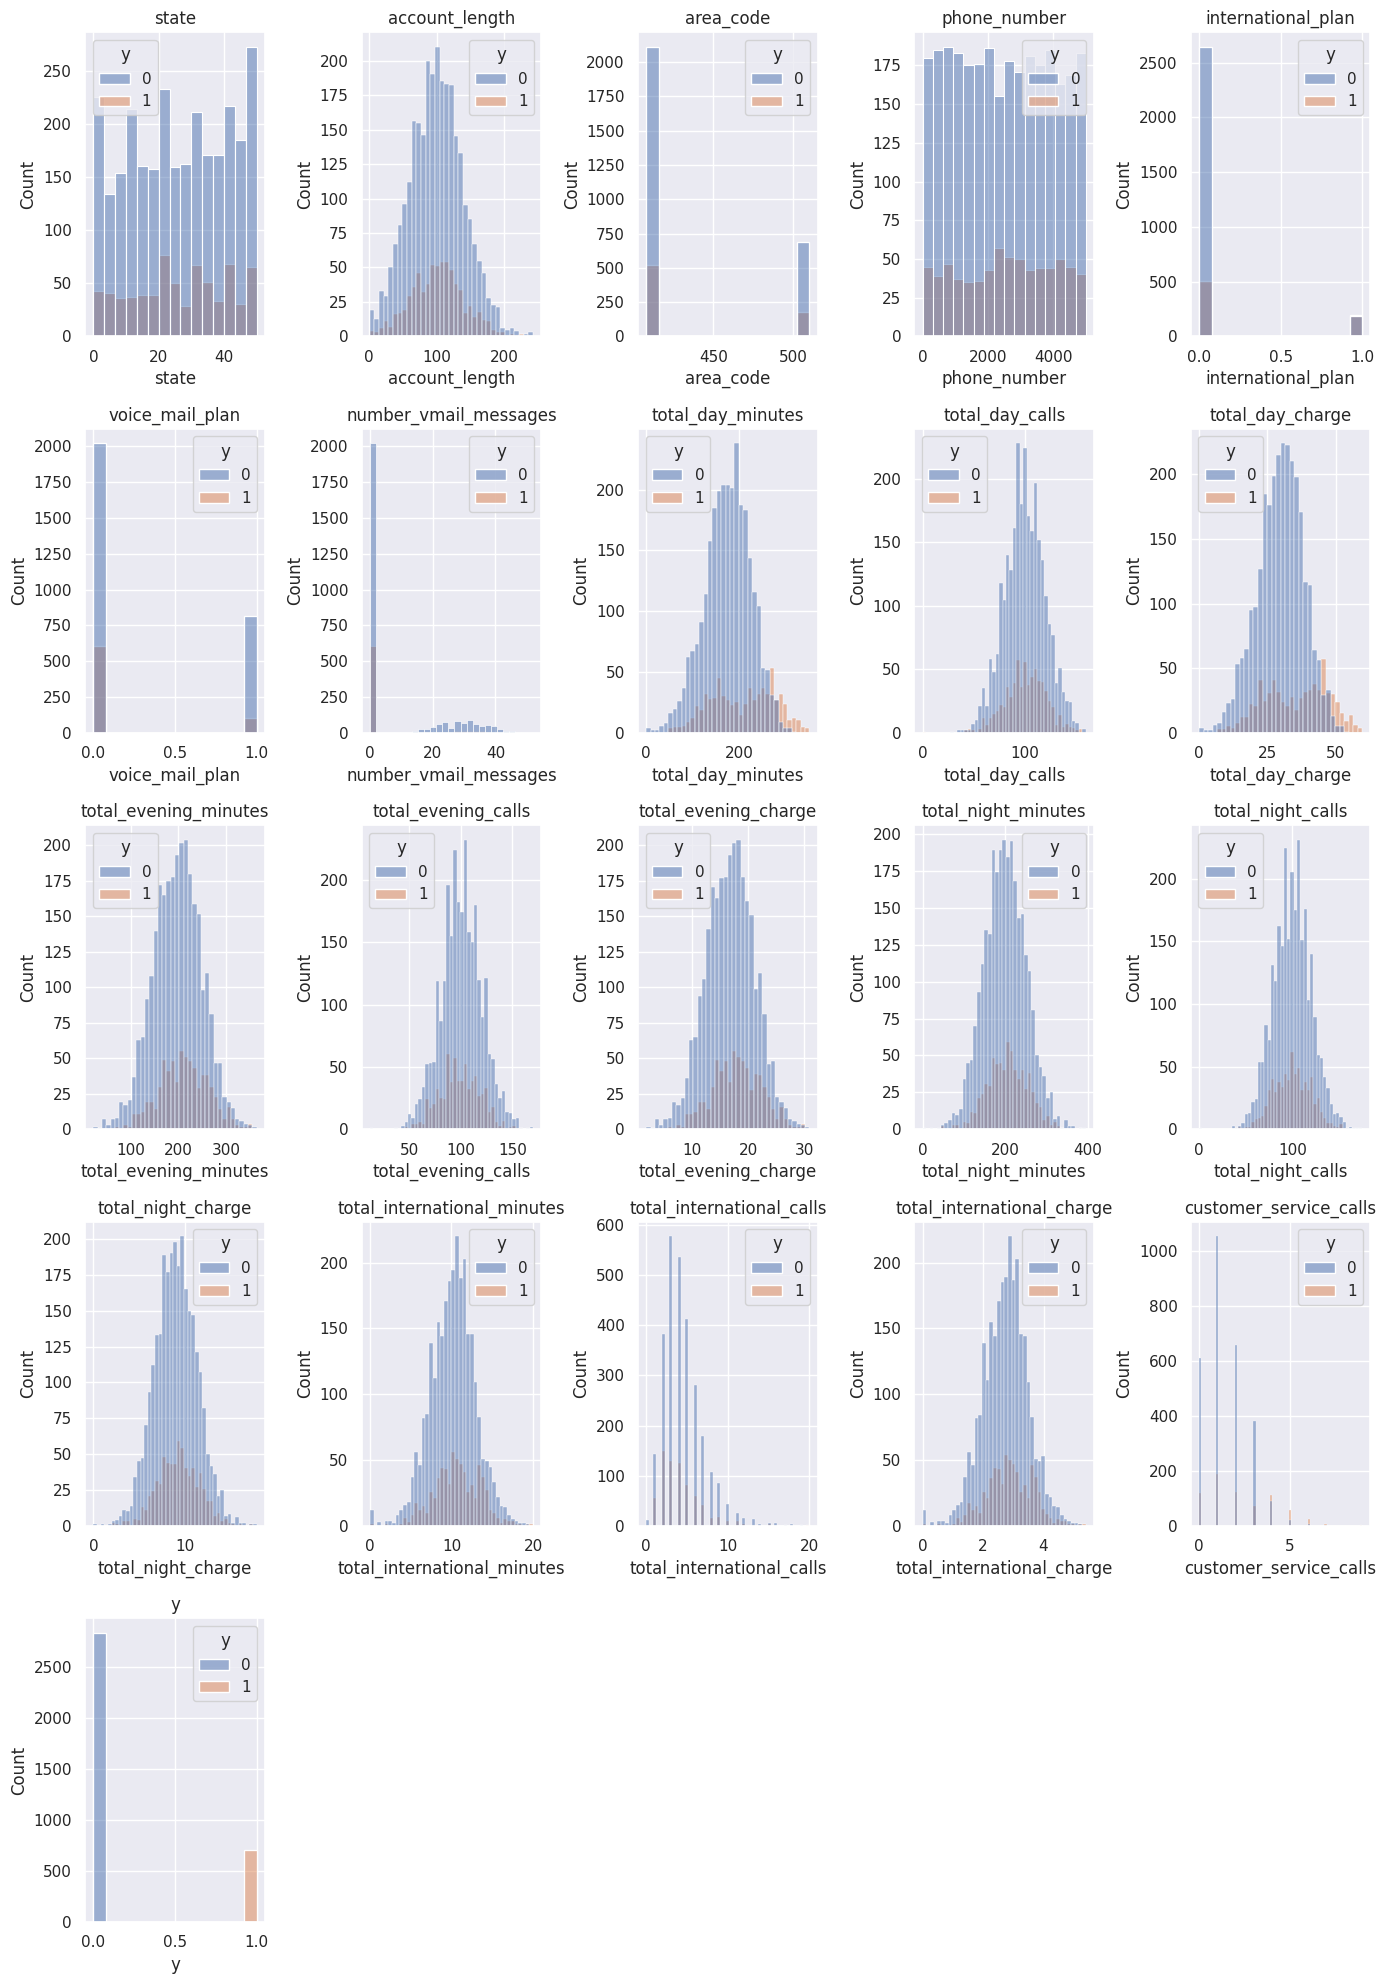

In [14]:
cols = col_sin_target + ['y']
n = len(cols)
ncols = 5
nrows = math.ceil(n / ncols)

fig, axes = plt.subplots(nrows, ncols, figsize=(14, 4*nrows))
axes = axes.flatten()

for ax, col in zip(axes, cols):
    sns.histplot(data=df_nodup, x=col, hue=target, ax=ax)
    ax.set_title(col)

for ax in axes[n:]:
    fig.delaxes(ax)

plt.tight_layout()
save_and_show('histplot_variables_explicativas.svg')

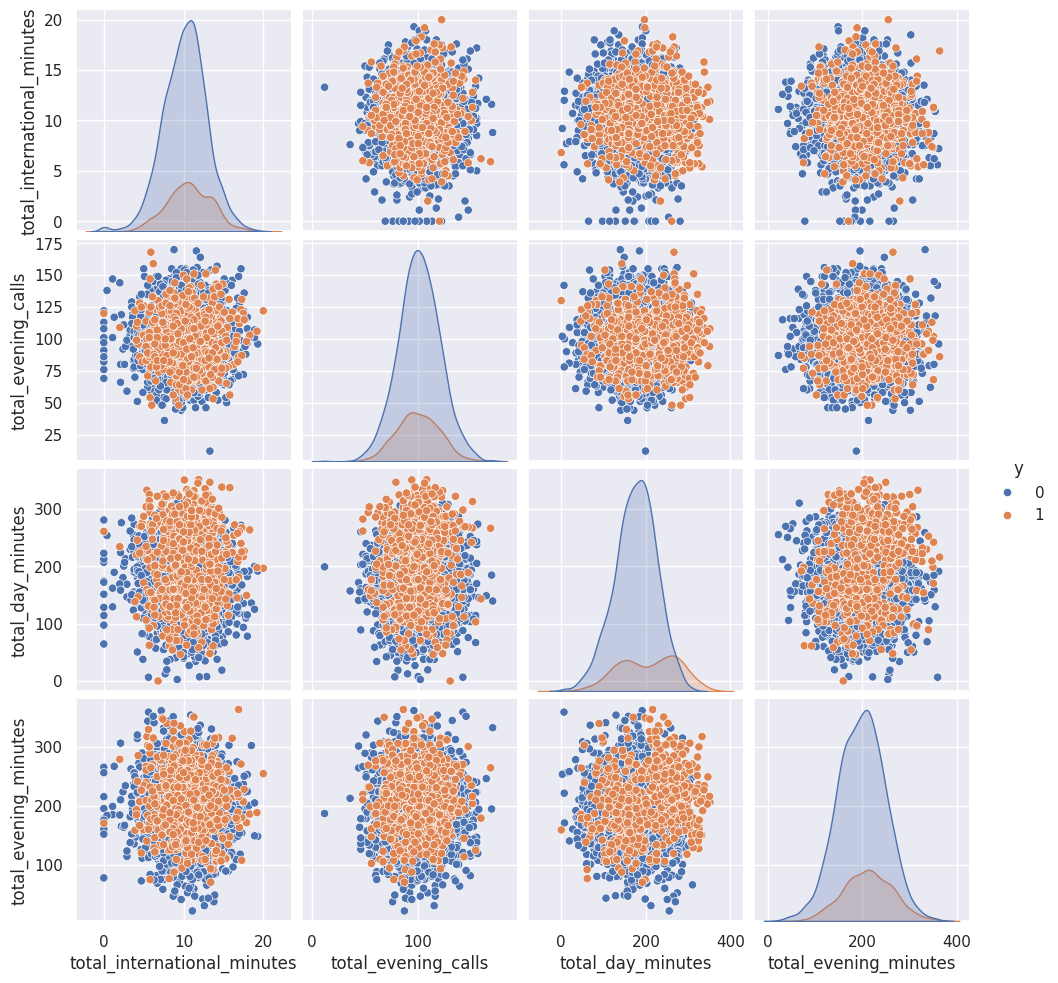

In [15]:
pairplot_cols = [
    c for c in ['y', 'total_international_minutes', 'total_evening_calls', 'total_day_minutes', 'total_evening_minutes']
    if c in df_nodup.columns
]

if len(pairplot_cols) >= 3:
    sns.pairplot(df_nodup[pairplot_cols], hue='y')


## 05.04 Análisis de la correlación entre varibles para estudiar la autocolinealidad

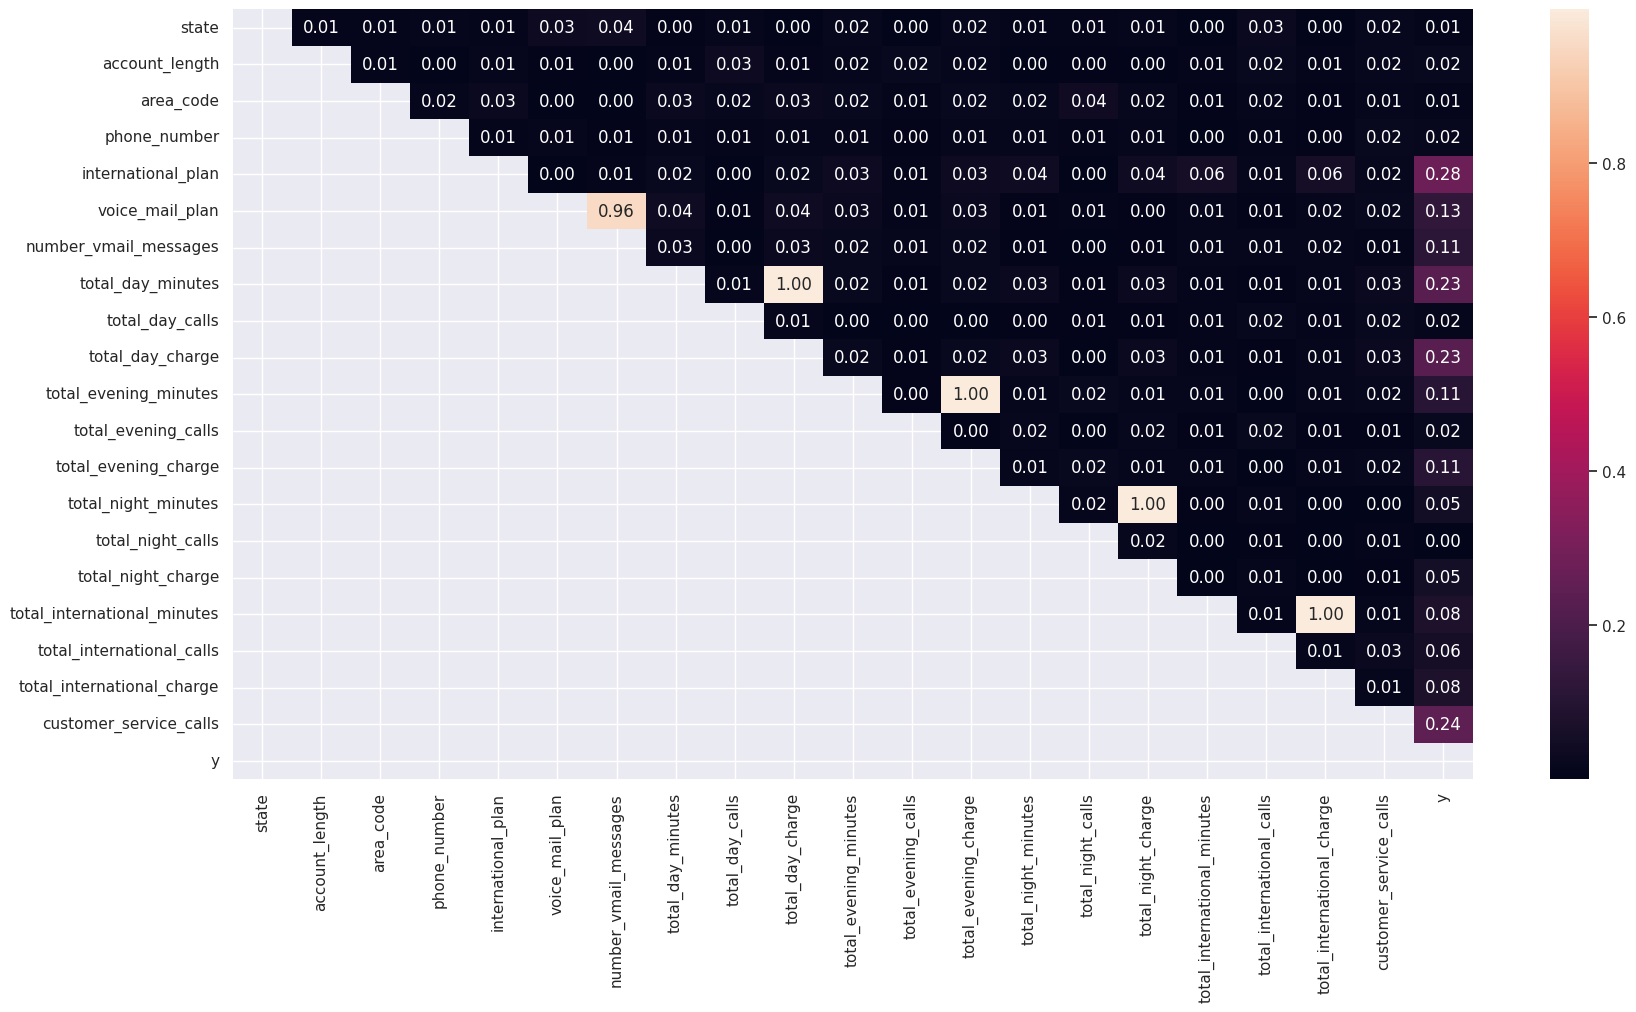

Variables eliminadas por correlación: ['number_vmail_messages', 'total_day_charge', 'total_evening_charge', 'total_night_charge', 'total_international_charge']


In [16]:
# Solo numéricas
corr_matrix = df_nodup.select_dtypes(include=np.number).corr().abs()

# Triángulo superior (para evitar duplicados)
upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
plt.figure(figsize=(20,10))
sns.heatmap(upper, annot=True, fmt=".2f")
save_and_show('heatmap_correlacion_superior.svg')

# Variables a eliminar por alta correlación
threshold = 0.95
to_drop = [col for col in upper.columns if any(upper[col] > threshold)]

print('Variables eliminadas por correlación:', to_drop)


## 05.03 Se decide eliminar el phone_number ya que no aporta info, es el número de cada persona (ID), también se elimina la columna state, ya que después de un entrenar la red el modelo RFE coge 5 variables dummy de esta, se podria dejar y pasar a categorica pero no tiene sentido ya que no es ordinal, más grande más peso y tampoco se puede dejar como categórcia, por lo que se decida eliminarla del análisis, ademas en el analisis EDA se ve que sigue el mismo comportamiento en todos los estados, si hay mas gente de un estado la proporcion de 1 y 0 aumenta proporcionalmente

In [17]:
cols_manual_drop = ['phone_number', 'state']
cols_drop_all = list(dict.fromkeys(cols_manual_drop + to_drop))

cols_drop_nondup = [c for c in cols_drop_all if c in df_nodup.columns]
cols_drop_dup = [c for c in cols_drop_all if c in df_dup.columns]

df_reduced_nondup = df_nodup.drop(columns=cols_drop_nondup).copy()
df_reduced_dup = df_dup.drop(columns=cols_drop_dup).copy()

print('Variables eliminadas finales:', cols_drop_all)
print('Shape sin duplicados:', df_reduced_nondup.shape)
print('Shape con duplicados:', df_reduced_dup.shape)


Variables eliminadas finales: ['phone_number', 'state', 'number_vmail_messages', 'total_day_charge', 'total_evening_charge', 'total_night_charge', 'total_international_charge']
Shape sin duplicados: (3538, 14)
Shape con duplicados: (9200, 14)


# 06 - Regresión logística y red neuronal

## 06.01 - Definir variables categóricas, continuas ...

In [18]:
feature_cols = [c for c in df_reduced_nondup.columns if c != 'y']
cat_cols = [c for c in ['area_code', 'international_plan', 'voice_mail_plan'] if c in feature_cols]

bin_cols = [c for c in ['international_plan', 'voice_mail_plan'] if c in cat_cols]
cat_cols_use = [c for c in cat_cols if c not in bin_cols]
num_cols = [col for col in feature_cols if col not in cat_cols]

print(num_cols)
print(cat_cols_use)
print(bin_cols)


['account_length', 'total_day_minutes', 'total_day_calls', 'total_evening_minutes', 'total_evening_calls', 'total_night_minutes', 'total_night_calls', 'total_international_minutes', 'total_international_calls', 'customer_service_calls']
['area_code']
['international_plan', 'voice_mail_plan']


## 06.02 - Separación en train y test


In [19]:
warnings.filterwarnings('ignore', category=ConvergenceWarning)

X = df_reduced_nondup.drop(columns=['y']).copy()
y = df_reduced_nondup['y'].astype(int).copy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=seed, stratify=y
)

print('Train shape:', X_train.shape)
print('Test shape :', X_test.shape)


Train shape: (2830, 13)
Test shape : (708, 13)


In [20]:
X_train.info()

<class 'pandas.core.frame.DataFrame'>
Index: 2830 entries, 3518 to 3382
Data columns (total 13 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   account_length               2830 non-null   int64  
 1   area_code                    2801 non-null   float64
 2   international_plan           2830 non-null   int64  
 3   voice_mail_plan              2830 non-null   int64  
 4   total_day_minutes            2830 non-null   float64
 5   total_day_calls              2830 non-null   int64  
 6   total_evening_minutes        2830 non-null   float64
 7   total_evening_calls          2830 non-null   int64  
 8   total_night_minutes          2811 non-null   float64
 9   total_night_calls            2807 non-null   float64
 10  total_international_minutes  2830 non-null   float64
 11  total_international_calls    2830 non-null   int64  
 12  customer_service_calls       2830 non-null   int64  
dtypes: float64(6), int64

## 06.03 - Imputación (ajustada solo con train)


In [21]:
# info de valores perdidos (dataset sin duplicados reducido)


info_nulos = pd.DataFrame({
    'Total Nulos': X_train.isna().sum(),
    'Porcentaje': X_train.isnull().mean() * 100
})

print(info_nulos[info_nulos['Total Nulos'] > 0].sort_values(by='Porcentaje', ascending=False))


                     Total Nulos  Porcentaje
area_code                     29    1.024735
total_night_calls             23    0.812721
total_night_minutes           19    0.671378


### 06.03.01 - Heatmap de perdidos


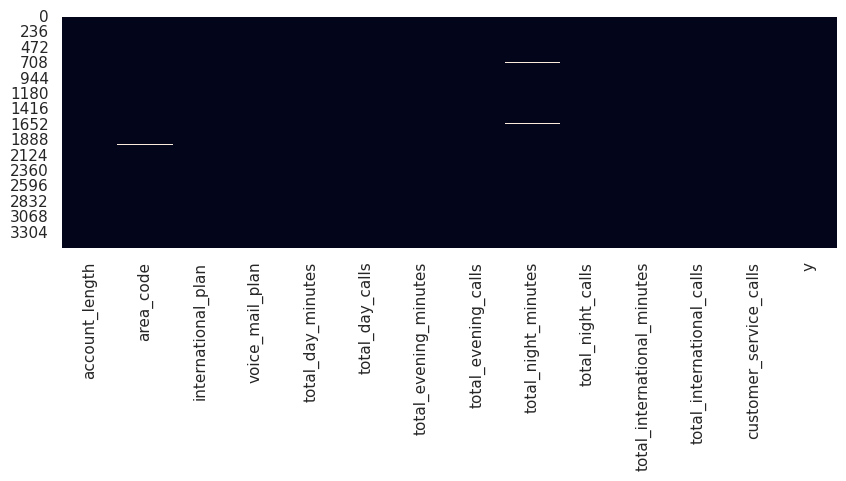

In [22]:
plt.figure(figsize=(10,3))
sns.heatmap(df_reduced_nondup.isnull(), cbar=False)
save_and_show('heatmap_nulos_dataset.svg')


### 06.03.02 - Correlación de perdidos


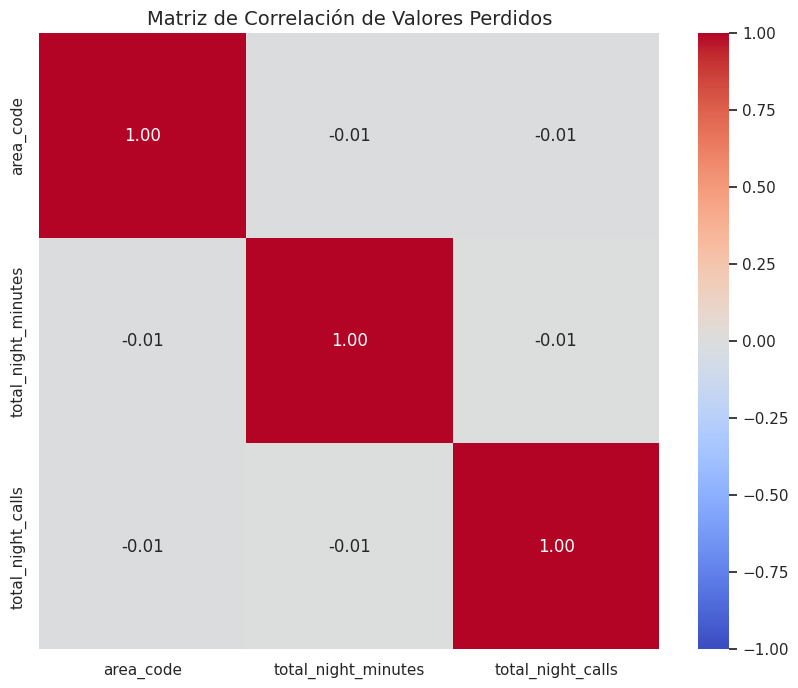

In [23]:
# Columnas con al menos un valor perdido
cols_con_nulos = df_reduced_nondup.columns[df_reduced_nondup.isnull().any()]

if len(cols_con_nulos) > 1:
    correlacion_nulos = df_reduced_nondup[cols_con_nulos].isnull().corr()

    plt.figure(figsize=(10, 8))
    sns.heatmap(correlacion_nulos, annot=True, cmap='coolwarm', vmin=-1, vmax=1, fmt='.2f')
    plt.title('Matriz de Correlación de Valores Perdidos', fontsize=14)
    save_and_show('heatmap_correlacion_nulos.svg')
else:
    print('No hay suficientes columnas con nulos para calcular correlación de perdidos.')


### 06.03.03 - Imputación con SimpleImputer (fit en train)


In [24]:
cat_cols_all = [c for c in ['area_code', 'international_plan', 'voice_mail_plan'] if c in X_train.columns]
num_cols_all = [c for c in X_train.columns if c not in cat_cols_all]

imp_num = SimpleImputer(strategy='median')
imp_cat = SimpleImputer(strategy='most_frequent')

X_train_imp = X_train.copy()
X_test_imp = X_test.copy()

if num_cols_all:
    X_train_imp[num_cols_all] = imp_num.fit_transform(X_train[num_cols_all])
    X_test_imp[num_cols_all] = imp_num.transform(X_test[num_cols_all])

if cat_cols_all:
    X_train_imp[cat_cols_all] = imp_cat.fit_transform(X_train[cat_cols_all])
    X_test_imp[cat_cols_all] = imp_cat.transform(X_test[cat_cols_all])

# Reasignación para que el modelado posterior use los datos imputados
X_train = X_train_imp
X_test = X_test_imp

# Dataset completo sin duplicados imputado con los imputers del train
X_all_nondup = df_reduced_nondup.drop(columns=['y']).copy()
if num_cols_all:
    X_all_nondup[num_cols_all] = imp_num.transform(X_all_nondup[num_cols_all])
if cat_cols_all:
    X_all_nondup[cat_cols_all] = imp_cat.transform(X_all_nondup[cat_cols_all])
df_imputed_nondup = pd.concat([X_all_nondup, df_reduced_nondup['y'].reset_index(drop=True)], axis=1)

print('Nulos en X_train tras imputación:', X_train.isna().sum().sum())
print('Nulos en X_test tras imputación :', X_test.isna().sum().sum())


Nulos en X_train tras imputación: 0
Nulos en X_test tras imputación : 0


### 06.03.04 - Imputación para dataset con duplicados (mismos imputers de train)


In [25]:
X_dup = df_reduced_dup.drop(columns=['y']).copy()

if num_cols_all:
    X_dup[num_cols_all] = imp_num.transform(X_dup[num_cols_all])
if cat_cols_all:
    X_dup[cat_cols_all] = imp_cat.transform(X_dup[cat_cols_all])

df_imputed_dup = pd.concat([X_dup, df_reduced_dup['y'].reset_index(drop=True)], axis=1)

print('Nulos tras SimpleImputer en dataset con duplicados:', df_imputed_dup.isna().sum().sum())


Nulos tras SimpleImputer en dataset con duplicados: 0


## 06.04 - Configuración del pipeline y del grid


In [26]:
col_transf = ColumnTransformer(
    transformers=[
        ("scaler", StandardScaler(), num_cols),
        ("ohe", OneHotEncoder(handle_unknown="ignore",
                              sparse_output=False,
                              drop="if_binary"),
         cat_cols_use),
         ("binary_pass", "passthrough", bin_cols)
    ],
    remainder="drop"
)

pipe = Pipeline(
    [('col_trasnf', col_transf),
     ('var_selection', RFE(LogisticRegression(random_state=seed, max_iter=1000), n_features_to_select=5)),
     ('Red_neuronal', MLPClassifier(random_state=seed, early_stopping=True, max_iter=1000))]
)

param_grid = {
    'Red_neuronal__hidden_layer_sizes': [(2,), (4,), (8,),(12,)],
    'Red_neuronal__activation': ['relu', 'tanh'],
    'Red_neuronal__alpha': [1e-4, 1e-3, 1e-2],
    'Red_neuronal__learning_rate_init': [1e-3, 1e-2]
}


grid_logistic = GridSearchCV(
    estimator=pipe,
    param_grid=param_grid,
    scoring='accuracy',
    cv=10,
    error_score='raise'
)


In [27]:
model_name = "../models/grid_logistic_v3.pkl"

if os.path.exists(model_name):
    print("Modelo encontrado. Cargando...")
    grid_logistic = joblib.load(model_name)

else:
    print("Entrenando modelo...")
    grid_logistic.fit(X_train, y_train)

    print("Guardando modelo...")
    joblib.dump(grid_logistic, model_name)


Modelo encontrado. Cargando...


## 06.05 - Análisis de los resultados del grid


In [28]:
# Mejor modelo del grid
best_model = grid_logistic.best_estimator_

# Step de preprocesado y selector
preprocess = best_model.named_steps["col_trasnf"]
selector = best_model.named_steps["var_selection"]

# Nombres tras ColumnTransformer
feature_names = preprocess.get_feature_names_out()

# Máscara de variables seleccionadas
support = selector.get_support()

# Variables finales
selected_features = feature_names[support]

print("Predictores finales:")
for f in selected_features:
    print(f)

Predictores finales:
scaler__total_day_minutes
scaler__total_evening_minutes
scaler__customer_service_calls
binary_pass__international_plan
binary_pass__voice_mail_plan


# Evaluacion logistic

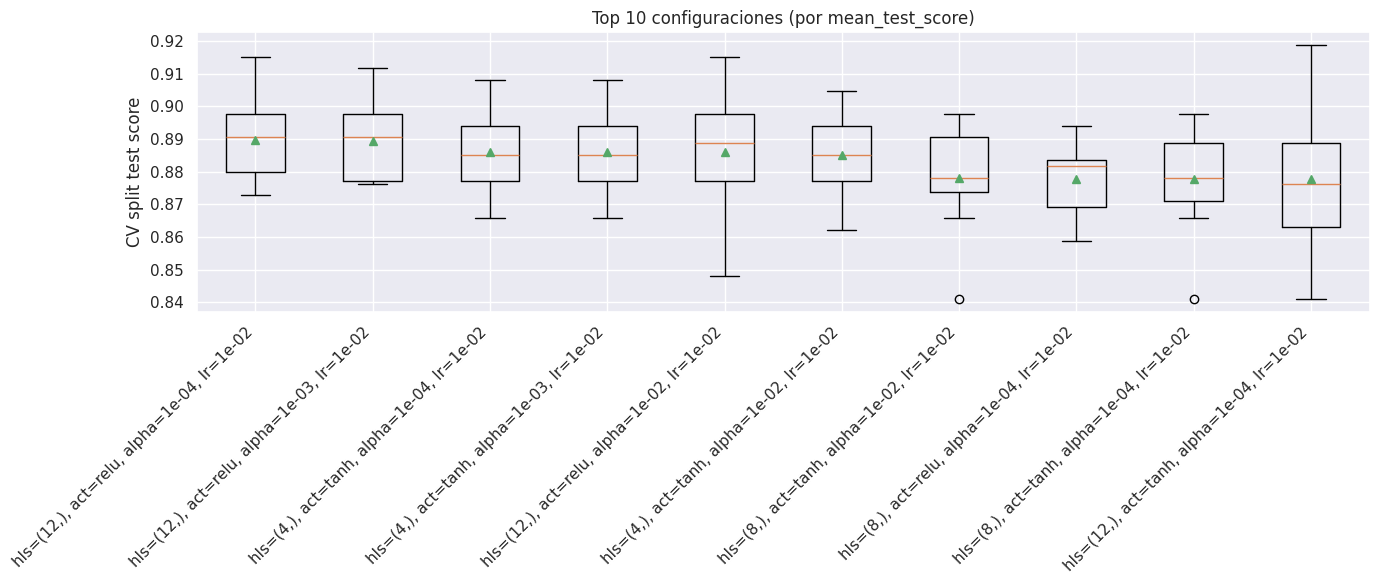

In [29]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# cv_results a DataFrame
cv = pd.DataFrame(grid_logistic.cv_results_)

# columnas de scores por fold
split_cols = [c for c in cv.columns if c.startswith("split") and c.endswith("_test_score")]

# ordenar y quedarte con Top 10 por mean_test_score (y menor std como desempate)
topN = 10
top = (cv.sort_values(["mean_test_score", "std_test_score"], ascending=[False, True])
         .head(topN)
         .reset_index(drop=True))

# construir etiquetas SOLO con los hiperparámetros de la red (como tú lo estabas analizando)
labels = []
data = []
for i in range(len(top)):
    row = top.loc[i]

    hls = row["param_Red_neuronal__hidden_layer_sizes"]
    act = row["param_Red_neuronal__activation"]
    alpha = row["param_Red_neuronal__alpha"]
    lr = row["param_Red_neuronal__learning_rate_init"]

    labels.append(f"hls={hls}, act={act}, alpha={alpha:.0e}, lr={lr:.0e}")
    data.append(top.loc[i, split_cols].astype(float).to_numpy())

plt.figure(figsize=(max(14, 1.2 * topN), 6))
plt.boxplot(data, labels=labels, showmeans=True)
plt.ylabel("CV split test score")
plt.title(f"Top {topN} configuraciones (por mean_test_score)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig('boxplot_topN_configuraciones_log.svg')
plt.show()

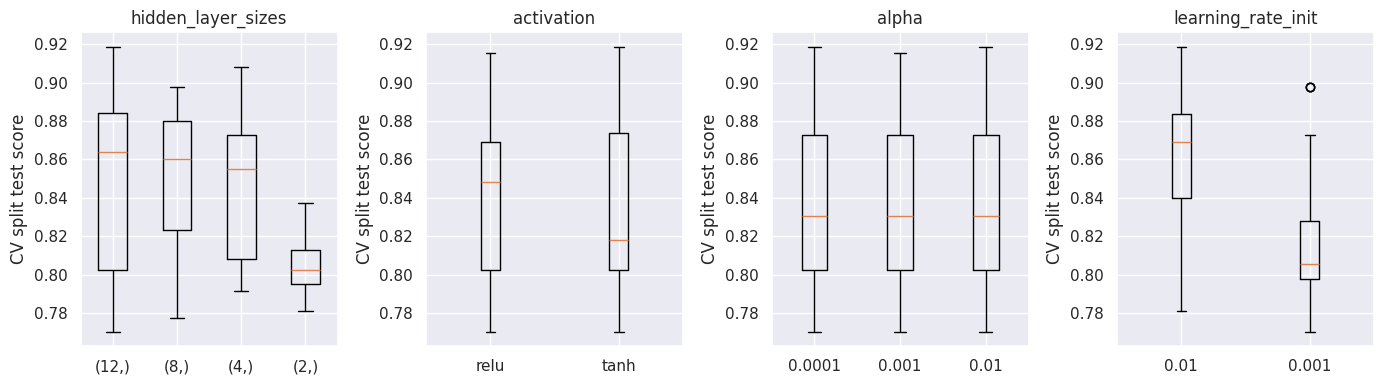

In [30]:

param_cols = [
    "param_Red_neuronal__hidden_layer_sizes",
    "param_Red_neuronal__activation",
    "param_Red_neuronal__alpha",
    "param_Red_neuronal__learning_rate_init"
]

ncols = 4
nrows = int(np.ceil(len(param_cols) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(14, 4*nrows), squeeze=False)
axes = axes.flatten()

for i, pc in enumerate(param_cols):
    dfp = cv[[pc] + split_cols].dropna(subset=[pc]).copy()
    dfp[pc] = dfp[pc].astype(str)

    long = dfp.melt(id_vars=[pc], value_vars=split_cols,
                    var_name="split", value_name="score").dropna(subset=["score"])
    # ordenar categorías por mediana (para que se lea mejor)
    med = long.groupby(pc)["score"].median().sort_values(ascending=False)
    cats = med.index.tolist()

    data = [long.loc[long[pc] == c, "score"].astype(float).to_numpy() for c in cats]

    ax = axes[i]
    ax.boxplot(data, labels=cats)
    ax.set_title(pc.replace("param_Red_neuronal__", ""))
    ax.set_ylabel("CV split test score")
    ax.tick_params(axis="x", rotation=0)

# borrar ejes sobrantes
for j in range(i+1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.savefig('boxplot_hiperparametros_log.svg')
plt.show()

In [31]:
third_params = top.loc[2]
print(third_params)
params = {
    'Red_neuronal__hidden_layer_sizes': third_params["param_Red_neuronal__hidden_layer_sizes"],
    'Red_neuronal__activation': third_params["param_Red_neuronal__activation"],
    'Red_neuronal__alpha': third_params["param_Red_neuronal__alpha"],
    'Red_neuronal__learning_rate_init': third_params["param_Red_neuronal__learning_rate_init"]
}

model_3 = grid_logistic.best_estimator_.set_params(**params)
model_3.fit(X_train, y_train)


mean_fit_time                                                                      0.305352
std_fit_time                                                                       0.028228
mean_score_time                                                                    0.005045
std_score_time                                                                      0.00081
param_Red_neuronal__activation                                                         tanh
param_Red_neuronal__alpha                                                            0.0001
param_Red_neuronal__hidden_layer_sizes                                                 (4,)
param_Red_neuronal__learning_rate_init                                                 0.01
params                                    {'Red_neuronal__activation': 'tanh', 'Red_neur...
split0_test_score                                                                  0.908127
split1_test_score                                                               

Pipeline(steps=[('col_trasnf',
                 ColumnTransformer(transformers=[('scaler', StandardScaler(),
                                                  ['account_length',
                                                   'total_day_minutes',
                                                   'total_day_calls',
                                                   'total_evening_minutes',
                                                   'total_evening_calls',
                                                   'total_night_minutes',
                                                   'total_night_calls',
                                                   'total_international_minutes',
                                                   'total_international_calls',
                                                   'customer_service_calls']),
                                                 ('ohe',
                                                  OneHotEncoder(drop='if_bi...
                                                                sparse_output=False),
                                                  ['area_code']),
                                                 ('binary_pass', 'passthrough',
                                                  ['international_plan',
                                                   'voice_mail_plan'])])),
                ('var_selection',
                 RFE(estimator=LogisticRegression(max_iter=1000,
                                                  random_state=13),
                     n_features_to_select=5)),
                ('Red_neuronal',
                 MLPClassifier(activation='tanh', early_stopping=True,
                               hidden_layer_sizes=(4,), learning_rate_init=0.01,
                               max_iter=1000, random_state=13))])

In [32]:
modelo_elegido_logistica = model_3

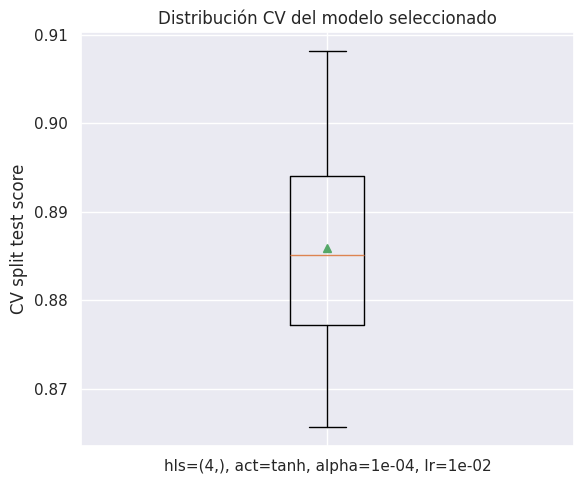

In [33]:
# columnas de scores por fold
split_cols = [c for c in cv.columns if c.startswith("split") and c.endswith("_test_score")]

# modelo 3 (índice 2)
row = top.loc[2]

# etiqueta
hls = row["param_Red_neuronal__hidden_layer_sizes"]
act = row["param_Red_neuronal__activation"]
alpha = row["param_Red_neuronal__alpha"]
lr = row["param_Red_neuronal__learning_rate_init"]

label = f"hls={hls}, act={act}, alpha={alpha:.0e}, lr={lr:.0e}"

# datos CV de ese modelo
data = [row[split_cols].astype(float).to_numpy()]

# boxplot
plt.figure(figsize=(6, 5))
plt.boxplot(data, labels=[label], showmeans=True)
plt.ylabel("CV split test score")
plt.title("Distribución CV del modelo seleccionado")
#plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.savefig('boxplot_modelo_elegido_log.svg')
plt.show()

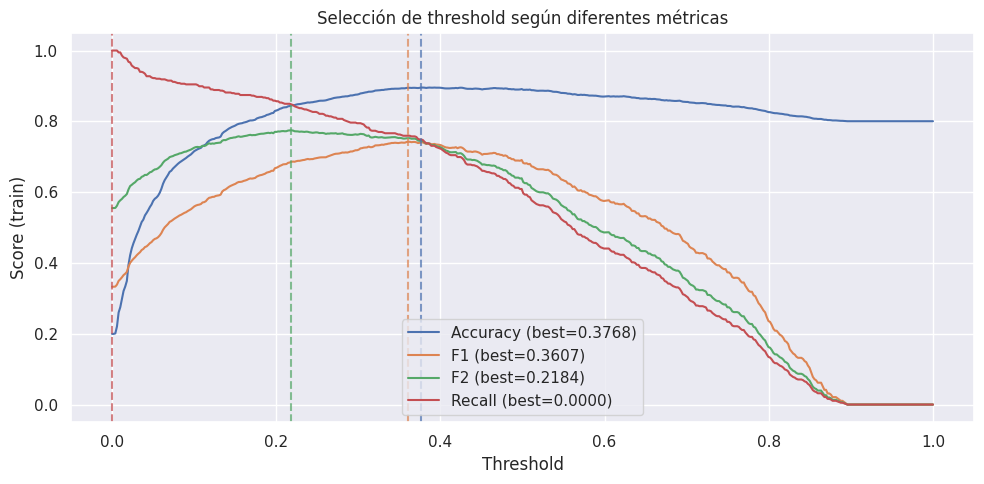

In [34]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, f1_score, fbeta_score, recall_score

# Probabilidades en TRAIN
y_prob_train = modelo_elegido_logistica.predict_proba(X_train)[:, 1]

# Barrido de thresholds
thresholds = np.linspace(0.0, 1.0, 500)

# Métricas
acc_scores, f1_scores, f2_scores, recall_scores = [], [], [], []

for t in thresholds:
    y_pred = (y_prob_train >= t).astype(int)

    acc_scores.append(accuracy_score(y_train, y_pred))
    f1_scores.append(f1_score(y_train, y_pred, zero_division=0))
    f2_scores.append(fbeta_score(y_train, y_pred, beta=2, zero_division=0))
    recall_scores.append(recall_score(y_train, y_pred, zero_division=0))

# Mejor threshold para cada métrica
best_acc_t = thresholds[np.argmax(acc_scores)]
best_f1_t = thresholds[np.argmax(f1_scores)]
best_f2_t = thresholds[np.argmax(f2_scores)]
best_rec_t = thresholds[np.argmax(recall_scores)]

# Plot
plt.figure(figsize=(10, 5))

# Dibujar curvas y guardar colores
line_acc, = plt.plot(thresholds, acc_scores,
                     label=f"Accuracy (best={best_acc_t:.4f})")
line_f1, = plt.plot(thresholds, f1_scores,
                    label=f"F1 (best={best_f1_t:.4f})")
line_f2, = plt.plot(thresholds, f2_scores,
                    label=f"F2 (best={best_f2_t:.4f})")
line_rec, = plt.plot(thresholds, recall_scores,
                     label=f"Recall (best={best_rec_t:.4f})")

# Líneas verticales con el mismo color
plt.axvline(best_acc_t, linestyle="--", alpha=0.7, color=line_acc.get_color())
plt.axvline(best_f1_t, linestyle="--", alpha=0.7, color=line_f1.get_color())
plt.axvline(best_f2_t, linestyle="--", alpha=0.7, color=line_f2.get_color())
plt.axvline(best_rec_t, linestyle="--", alpha=0.7, color=line_rec.get_color())

plt.xlabel("Threshold")
plt.ylabel("Score (train)")
plt.title("Selección de threshold según diferentes métricas")
plt.legend()
plt.tight_layout()
plt.savefig('threshold_selection_log.svg')
plt.show()


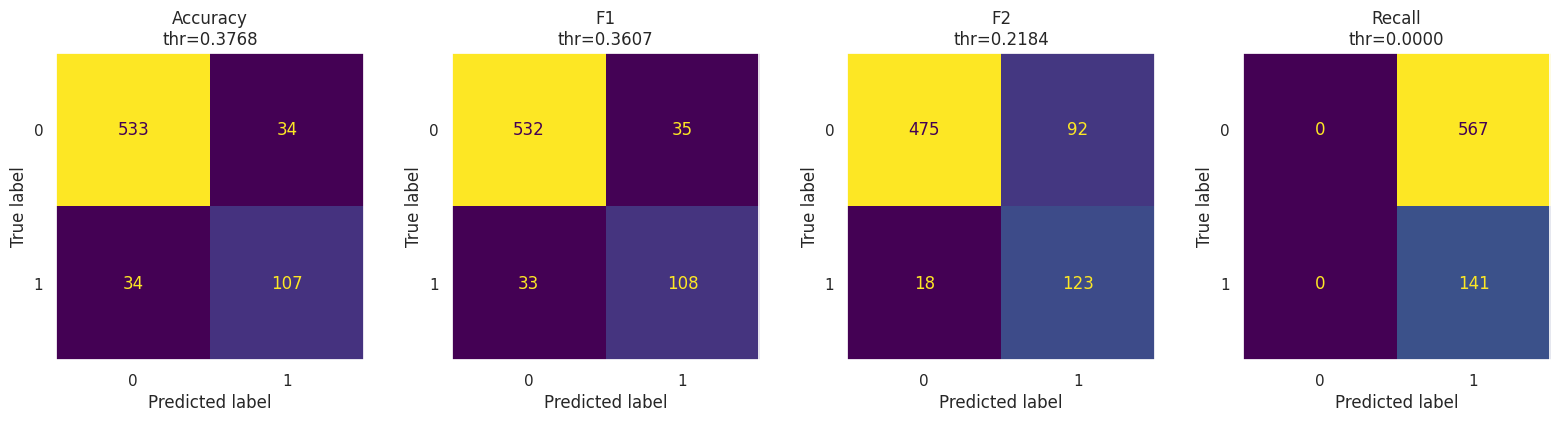

In [35]:
# Probabilidades
y_prob_test = modelo_elegido_logistica.predict_proba(X_test)[:, 1]

# thresholds óptimos que ya tienes
thr_dict = {
    "Accuracy": best_acc_t,
    "F1": best_f1_t,
    "F2": best_f2_t,
    "Recall": best_rec_t
}

fig, axes = plt.subplots(1, 4, figsize=(16, 4))

for i, (name, thr) in enumerate(thr_dict.items()):
    y_pred = (y_prob_test >= thr).astype(int)
    cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

    ConfusionMatrixDisplay(cm, display_labels=[0, 1]).plot(
        values_format="d", ax=axes[i], colorbar=False
    )
    axes[i].set_title(f"{name}\nthr={thr:.4f}")
    axes[i].grid(False) 

plt.tight_layout()
plt.savefig('confusion_matrices_thresholds_log.svg')
plt.show()

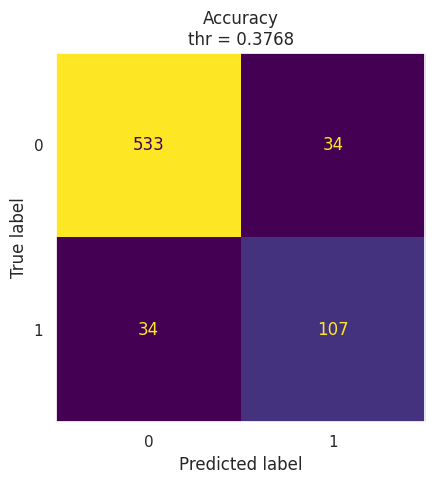

In [36]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Probabilidades
y_prob_test = modelo_elegido_logistica.predict_proba(X_test)[:, 1]

# Threshold óptimo
thr = best_acc_t

# Predicción binaria
y_pred = (y_prob_test >= thr).astype(int)

# Matriz de confusión
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

# Plot
fig, ax = plt.subplots(figsize=(6, 5))

ConfusionMatrixDisplay(cm, display_labels=[0, 1]).plot(
    values_format="d",
    ax=ax,
    colorbar=False
)

ax.set_title(f"Accuracy\nthr = {thr:.4f}")
ax.grid(False)

plt.tight_layout()
plt.savefig('confusion_matrix_final_log.svg')
plt.show()

In [37]:
modelo_elegido_logistica

Pipeline(steps=[('col_trasnf',
                 ColumnTransformer(transformers=[('scaler', StandardScaler(),
                                                  ['account_length',
                                                   'total_day_minutes',
                                                   'total_day_calls',
                                                   'total_evening_minutes',
                                                   'total_evening_calls',
                                                   'total_night_minutes',
                                                   'total_night_calls',
                                                   'total_international_minutes',
                                                   'total_international_calls',
                                                   'customer_service_calls']),
                                                 ('ohe',
                                                  OneHotEncoder(drop='if_bi...
                                                                sparse_output=False),
                                                  ['area_code']),
                                                 ('binary_pass', 'passthrough',
                                                  ['international_plan',
                                                   'voice_mail_plan'])])),
                ('var_selection',
                 RFE(estimator=LogisticRegression(max_iter=1000,
                                                  random_state=13),
                     n_features_to_select=5)),
                ('Red_neuronal',
                 MLPClassifier(activation='tanh', early_stopping=True,
                               hidden_layer_sizes=(4,), learning_rate_init=0.01,
                               max_iter=1000, random_state=13))])

# 07 - Árbol de decisión y red neuronal

## 07.01 - Train y test, se usan los mismos valores para train y test 

## 07.02 - Configuración del Pipeline y entrenamiento

In [38]:
col_transf = ColumnTransformer(
    transformers=[
        ("scaler", StandardScaler(), num_cols),
        ("ohe", OneHotEncoder(handle_unknown="ignore",
                              sparse_output=False,
                              drop="if_binary"),
         cat_cols_use),
         ("binary_pass", "passthrough", bin_cols)
    ],
    remainder="drop"
)

selector = SelectFromModel(estimator=DecisionTreeClassifier(random_state=seed), max_features=5)

pipe = Pipeline(
    [('col_trasnf', col_transf),
     ('var_selection', selector),
     ('Red_neuronal', MLPClassifier(random_state=seed, early_stopping=True, max_iter=1000))]
)

param_grid = {
    'Red_neuronal__hidden_layer_sizes': [(2,), (4,), (8,),(12,)],
    'Red_neuronal__activation': ['relu', 'tanh'],
    'Red_neuronal__alpha': [1e-4, 1e-3, 1e-2],
    'Red_neuronal__learning_rate_init': [1e-3, 1e-2]
}

grid_tree = GridSearchCV(
    estimator=pipe,
    param_grid=param_grid,
    scoring='recall',
    cv=10,
    error_score='raise'
)


In [39]:
model_name_tree = "../models/grid_tree_v5.pkl"

if os.path.exists(model_name_tree):
    print("Modelo encontrado. Cargando...")
    grid_tree = joblib.load(model_name_tree)

else:
    print("Entrenando modelo...")
    grid_tree.fit(X_train, y_train)

    print("Guardando modelo...")
    joblib.dump(grid_tree, model_name_tree)


Modelo encontrado. Cargando...


In [40]:
# Nuevo, ver varianza expliada por las variables seleccionadas por el selector de árbol
import pandas as pd
import matplotlib.pyplot as plt

# 1. Recuperar el mejor pipeline encontrado por el GridSearch
best_pipe = grid_tree.best_estimator_

# 2. Recuperar los nombres de las columnas transformadas (OHE crea nuevas columnas)
# Accedemos al paso 'col_trasnf' del pipeline
preprocessor = best_pipe.named_steps['col_trasnf']
feature_names = preprocessor.get_feature_names_out()

# 3. Recuperar el árbol de decisión entrenado dentro del selector
# Accedemos al paso 'var_selection' y luego a su estimador interno
selector = best_pipe.named_steps['var_selection']
tree_estimator = selector.estimator_

# 4. Extraer las importancias (Gini importance)
importances = tree_estimator.feature_importances_

# 5. Crear un DataFrame para verlo ordenado
df_importances = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
}).sort_values(by='Importance', ascending=False)

# Mostrar las top 10
print(df_importances.head(10))

                                Feature  Importance
1             scaler__total_day_minutes    0.257511
9        scaler__customer_service_calls    0.125242
3         scaler__total_evening_minutes    0.120033
8     scaler__total_international_calls    0.098213
13      binary_pass__international_plan    0.085142
7   scaler__total_international_minutes    0.068676
5           scaler__total_night_minutes    0.068666
14         binary_pass__voice_mail_plan    0.060813
2               scaler__total_day_calls    0.030687
4           scaler__total_evening_calls    0.028717


In [41]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. Recuperar el mejor pipeline encontrado por el GridSearch
best_pipe = grid_tree.best_estimator_

# 2. Recuperar los nombres de las columnas transformadas (OHE crea nuevas columnas)
# Accedemos al paso 'col_trasnf' del pipeline
preprocessor = best_pipe.named_steps['col_trasnf']
feature_names = preprocessor.get_feature_names_out()

# 3. Recuperar el árbol de decisión entrenado dentro del selector
# Accedemos al paso 'var_selection' y luego a su estimador interno
selector = best_pipe.named_steps['var_selection']
tree_estimator = selector.estimator_

# 4. Extraer las importancias (Gini importance)
importances = tree_estimator.feature_importances_

# 5. Crear un DataFrame para verlo ordenado
df_importances = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
}).sort_values(by='Importance', ascending=False)

# Mostrar las top 10
print(df_importances.head(10))

                                Feature  Importance
1             scaler__total_day_minutes    0.257511
9        scaler__customer_service_calls    0.125242
3         scaler__total_evening_minutes    0.120033
8     scaler__total_international_calls    0.098213
13      binary_pass__international_plan    0.085142
7   scaler__total_international_minutes    0.068676
5           scaler__total_night_minutes    0.068666
14         binary_pass__voice_mail_plan    0.060813
2               scaler__total_day_calls    0.030687
4           scaler__total_evening_calls    0.028717


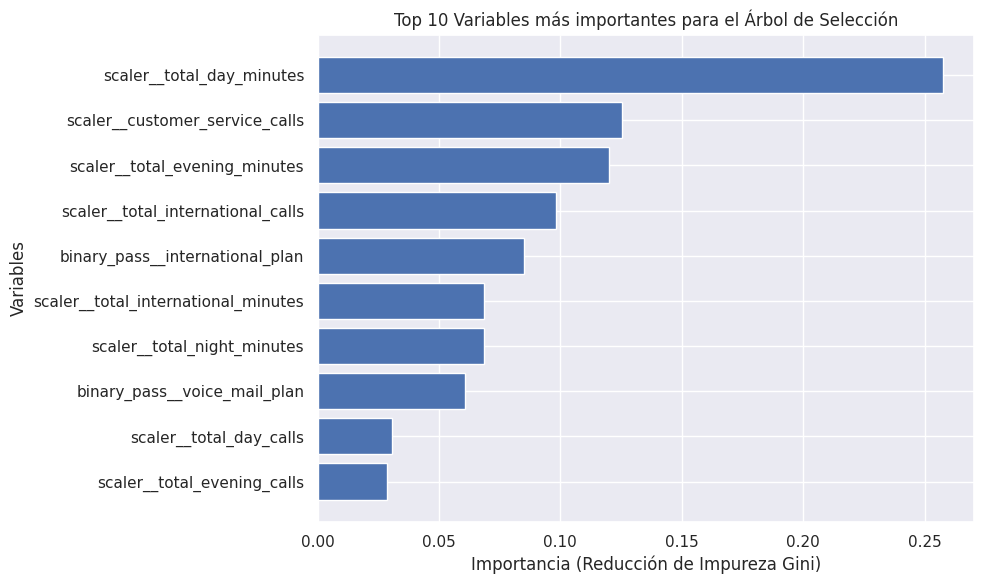

In [42]:
plt.figure(figsize=(10, 6))
plt.barh(df_importances['Feature'][:10], df_importances['Importance'][:10])
plt.xlabel('Importancia (Reducción de Impureza Gini)')
plt.ylabel('Variables')
plt.title('Top 10 Variables más importantes para el Árbol de Selección')
plt.gca().invert_yaxis() # Para que la más importante salga arriba
# incluir en la imagen el nombre completo de las variables (aunque sean largas)
plt.tight_layout()
plt.savefig('importancia_variables_arbol_log.svg')
plt.show()

In [43]:
# Máscara booleana de qué variables fueron seleccionadas
mask_selected = selector.get_support()
selected_features = feature_names[mask_selected]
print("Variables que llegaron a la Red Neuronal:", selected_features)

Variables que llegaron a la Red Neuronal: ['scaler__total_day_minutes' 'scaler__total_evening_minutes'
 'scaler__total_international_calls' 'scaler__customer_service_calls'
 'binary_pass__international_plan']


# Evaluacion modelo gridtree

In [44]:
# Mejor modelo del grid
best_model = grid_tree.best_estimator_

# Step de preprocesado y selector
preprocess = best_model.named_steps["col_trasnf"]
selector = best_model.named_steps["var_selection"]

# Nombres tras ColumnTransformer
feature_names = preprocess.get_feature_names_out()

# Máscara de variables seleccionadas
support = selector.get_support()

# Variables finales
selected_features = feature_names[support]

print("Predictores finales:")
for f in selected_features:
    print(f)

Predictores finales:
scaler__total_day_minutes
scaler__total_evening_minutes
scaler__total_international_calls
scaler__customer_service_calls
binary_pass__international_plan


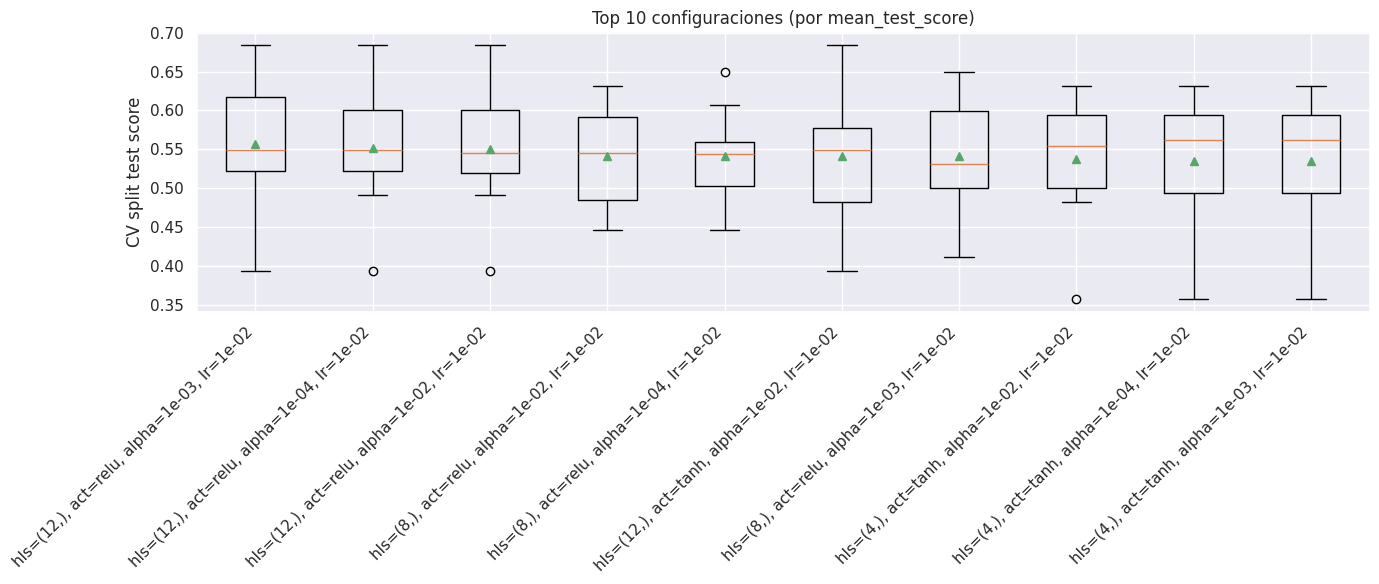

In [45]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# cv_results a DataFrame
cv = pd.DataFrame(grid_tree.cv_results_)

# columnas de scores por fold
split_cols = [c for c in cv.columns if c.startswith("split") and c.endswith("_test_score")]

# ordenar y quedarte con Top 10 por mean_test_score (y menor std como desempate)
topN = 10
top = (cv.sort_values(["mean_test_score", "std_test_score"], ascending=[False, True])
         .head(topN)
         .reset_index(drop=True))

# construir etiquetas SOLO con los hiperparámetros de la red (como tú lo estabas analizando)
labels = []
data = []
for i in range(len(top)):
    row = top.loc[i]

    hls = row["param_Red_neuronal__hidden_layer_sizes"]
    act = row["param_Red_neuronal__activation"]
    alpha = row["param_Red_neuronal__alpha"]
    lr = row["param_Red_neuronal__learning_rate_init"]

    labels.append(f"hls={hls}, act={act}, alpha={alpha:.0e}, lr={lr:.0e}")
    data.append(top.loc[i, split_cols].astype(float).to_numpy())

plt.figure(figsize=(max(14, 1.2 * topN), 6))
plt.boxplot(data, labels=labels, showmeans=True)
plt.ylabel("CV split test score")
plt.title(f"Top {topN} configuraciones (por mean_test_score)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig('boxplot_topN_configuraciones_tree_log.svg')
plt.show()

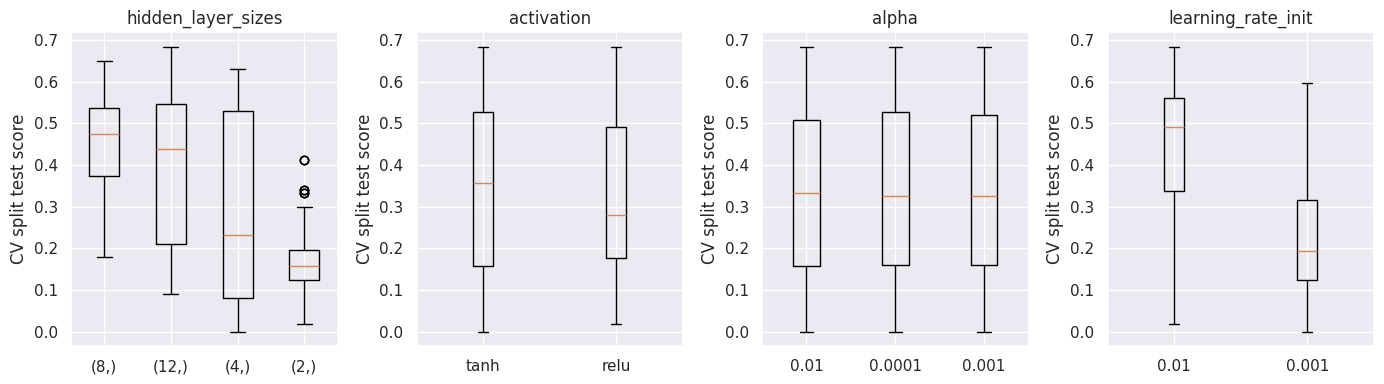

In [46]:

param_cols = [
    "param_Red_neuronal__hidden_layer_sizes",
    "param_Red_neuronal__activation",
    "param_Red_neuronal__alpha",
    "param_Red_neuronal__learning_rate_init"
]

ncols = 4
nrows = int(np.ceil(len(param_cols) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(14, 4*nrows), squeeze=False)
axes = axes.flatten()

for i, pc in enumerate(param_cols):
    dfp = cv[[pc] + split_cols].dropna(subset=[pc]).copy()
    dfp[pc] = dfp[pc].astype(str)

    long = dfp.melt(id_vars=[pc], value_vars=split_cols,
                    var_name="split", value_name="score").dropna(subset=["score"])
    # ordenar categorías por mediana (para que se lea mejor)
    med = long.groupby(pc)["score"].median().sort_values(ascending=False)
    cats = med.index.tolist()

    data = [long.loc[long[pc] == c, "score"].astype(float).to_numpy() for c in cats]

    ax = axes[i]
    ax.boxplot(data, labels=cats)
    ax.set_title(pc.replace("param_Red_neuronal__", ""))
    ax.set_ylabel("CV split test score")
    ax.tick_params(axis="x", rotation=0)

# borrar ejes sobrantes
for j in range(i+1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
# figuras folder
plt.savefig('')
plt.savefig('boxplot_hiperparametros_tree.svg')
plt.show()

In [47]:
third_params = top.loc[3]
print(third_params)
params = {
    'Red_neuronal__hidden_layer_sizes': third_params["param_Red_neuronal__hidden_layer_sizes"],
    'Red_neuronal__activation': third_params["param_Red_neuronal__activation"],
    'Red_neuronal__alpha': third_params["param_Red_neuronal__alpha"],
    'Red_neuronal__learning_rate_init': third_params["param_Red_neuronal__learning_rate_init"]
}

model_3 = grid_tree.best_estimator_.set_params(**params)
model_3.fit(X_train, y_train)
modelo_elegido_tree = model_3


mean_fit_time                                                                      0.114351
std_fit_time                                                                       0.023027
mean_score_time                                                                    0.005095
std_score_time                                                                     0.000819
param_Red_neuronal__activation                                                         relu
param_Red_neuronal__alpha                                                              0.01
param_Red_neuronal__hidden_layer_sizes                                                 (8,)
param_Red_neuronal__learning_rate_init                                                 0.01
params                                    {'Red_neuronal__activation': 'relu', 'Red_neur...
split0_test_score                                                                  0.473684
split1_test_score                                                               

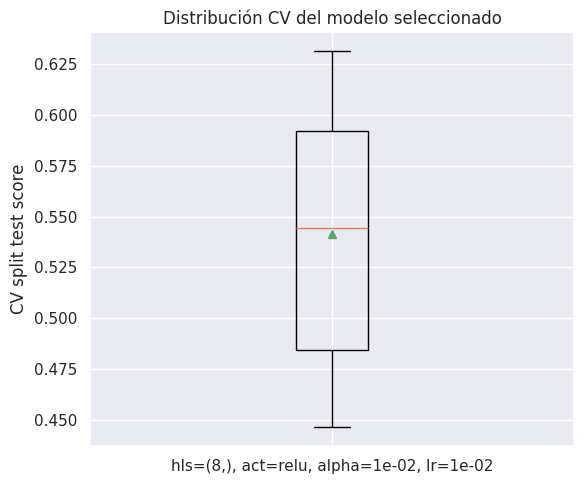

In [48]:
# columnas de scores por fold
split_cols = [c for c in cv.columns if c.startswith("split") and c.endswith("_test_score")]

# modelo 3 (índice 2)
row = top.loc[3]

# etiqueta
hls = row["param_Red_neuronal__hidden_layer_sizes"]
act = row["param_Red_neuronal__activation"]
alpha = row["param_Red_neuronal__alpha"]
lr = row["param_Red_neuronal__learning_rate_init"]

label = f"hls={hls}, act={act}, alpha={alpha:.0e}, lr={lr:.0e}"

# datos CV de ese modelo
data = [row[split_cols].astype(float).to_numpy()]

# boxplot
plt.figure(figsize=(6, 5))
plt.boxplot(data, labels=[label], showmeans=True)
plt.ylabel("CV split test score")
plt.title("Distribución CV del modelo seleccionado")
#plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.savefig('boxplot_modelo_elegido_tree.svg')
plt.show()

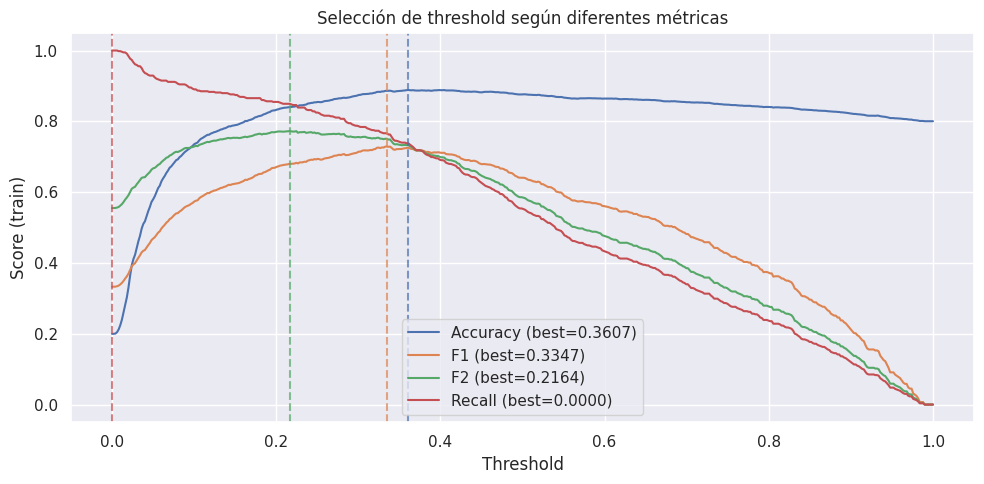

In [49]:
# Probabilidades en TRAIN
y_prob_train = modelo_elegido_tree.predict_proba(X_train)[:, 1]

# Barrido de thresholds
thresholds = np.linspace(0.0, 1.0, 500)

# Métricas
acc_scores, f1_scores, f2_scores, recall_scores = [], [], [], []

for t in thresholds:
    y_pred = (y_prob_train >= t).astype(int)

    acc_scores.append(accuracy_score(y_train, y_pred))
    f1_scores.append(f1_score(y_train, y_pred, zero_division=0))
    f2_scores.append(fbeta_score(y_train, y_pred, beta=2, zero_division=0))
    recall_scores.append(recall_score(y_train, y_pred, zero_division=0))

# Mejor threshold para cada métrica
best_acc_t = thresholds[np.argmax(acc_scores)]
best_f1_t = thresholds[np.argmax(f1_scores)]
best_f2_t = thresholds[np.argmax(f2_scores)]
best_rec_t = thresholds[np.argmax(recall_scores)]

# Plot
plt.figure(figsize=(10, 5))

# Dibujar curvas y guardar colores
line_acc, = plt.plot(thresholds, acc_scores,
                     label=f"Accuracy (best={best_acc_t:.4f})")
line_f1, = plt.plot(thresholds, f1_scores,
                    label=f"F1 (best={best_f1_t:.4f})")
line_f2, = plt.plot(thresholds, f2_scores,
                    label=f"F2 (best={best_f2_t:.4f})")
line_rec, = plt.plot(thresholds, recall_scores,
                     label=f"Recall (best={best_rec_t:.4f})")

# Líneas verticales con el mismo color
plt.axvline(best_acc_t, linestyle="--", alpha=0.7, color=line_acc.get_color())
plt.axvline(best_f1_t, linestyle="--", alpha=0.7, color=line_f1.get_color())
plt.axvline(best_f2_t, linestyle="--", alpha=0.7, color=line_f2.get_color())
plt.axvline(best_rec_t, linestyle="--", alpha=0.7, color=line_rec.get_color())

plt.xlabel("Threshold")
plt.ylabel("Score (train)")
plt.title("Selección de threshold según diferentes métricas")
plt.legend()
plt.tight_layout()
plt.savefig('threshold_selection_tree.svg')
plt.show()


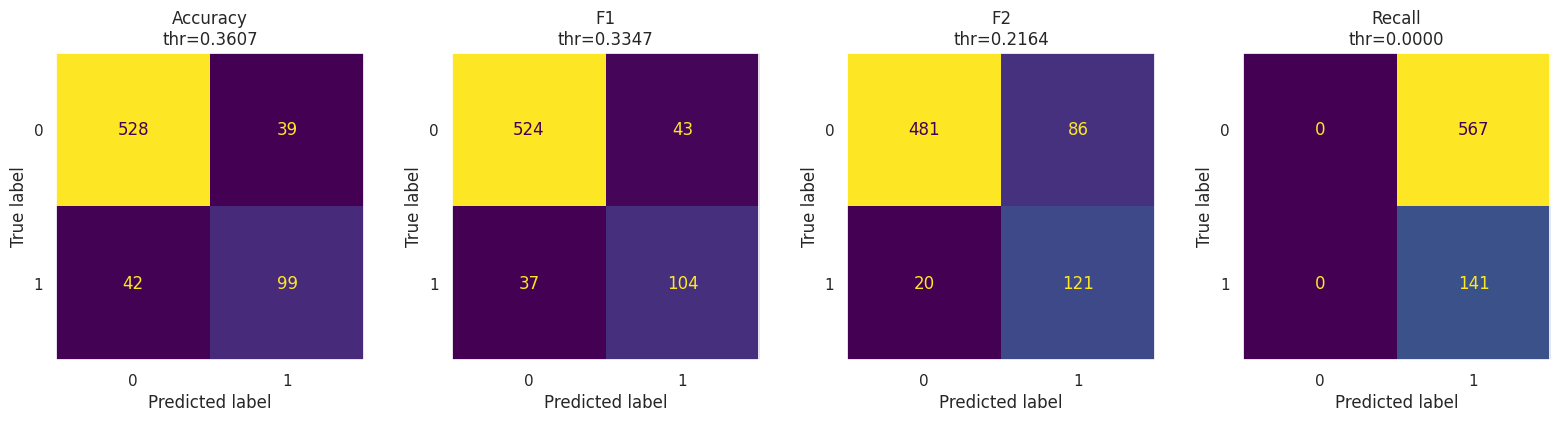

In [50]:
# Probabilidades
y_prob_test = modelo_elegido_tree.predict_proba(X_test)[:, 1]

# thresholds óptimos que ya tienes
thr_dict = {
    "Accuracy": best_acc_t,
    "F1": best_f1_t,
    "F2": best_f2_t,
    "Recall": best_rec_t
}

fig, axes = plt.subplots(1, 4, figsize=(16, 4))

for i, (name, thr) in enumerate(thr_dict.items()):
    y_pred = (y_prob_test >= thr).astype(int)
    cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

    ConfusionMatrixDisplay(cm, display_labels=[0, 1]).plot(
        values_format="d", ax=axes[i], colorbar=False
    )
    axes[i].set_title(f"{name}\nthr={thr:.4f}")
    axes[i].grid(False)   

plt.tight_layout()
plt.savefig('confusion_matrices_thresholds_tree.svg')  
plt.show()

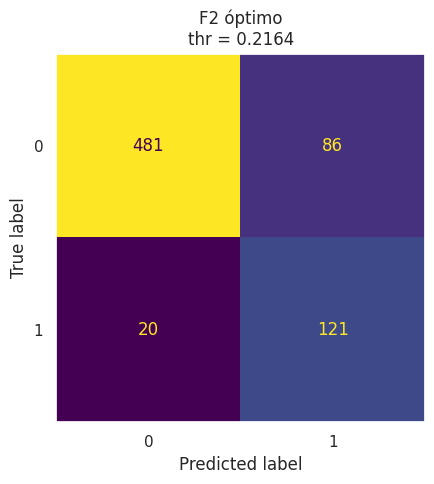

In [51]:

y_prob_test = modelo_elegido_tree.predict_proba(X_test)[:, 1]

# Threshold óptimo
thr = best_f2_t

# Predicción binaria
y_pred = (y_prob_test >= thr).astype(int)

# Matriz de confusión
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

# Plot
fig, ax = plt.subplots(figsize=(6, 5))

ConfusionMatrixDisplay(cm, display_labels=[0, 1]).plot(
    values_format="d",
    ax=ax,
    colorbar=False
)

ax.set_title(f"F2 óptimo\nthr = {thr:.4f}")
ax.grid(False)

plt.tight_layout()
plt.savefig('confusion_matrix_final_tree.svg')
plt.show()

# Ensemble

Generando predicciones Out-of-Fold con CV (10 folds)...
Predicciones OOF generadas. Optimizando pesos...

¡Configuración Óptima Encontrada (Validación Robusta)!
Peso Pipeline 1 (Grid/Logística): 0.58
Peso Pipeline 2 (Tree/Árbol):     0.42
Threshold óptimo:                 0.35

=== RESULTADOS FINALES EN TEST ===
Accuracy:  0.9096
Recall:    0.8085
Precision: 0.7550
F1 Score:  0.7808


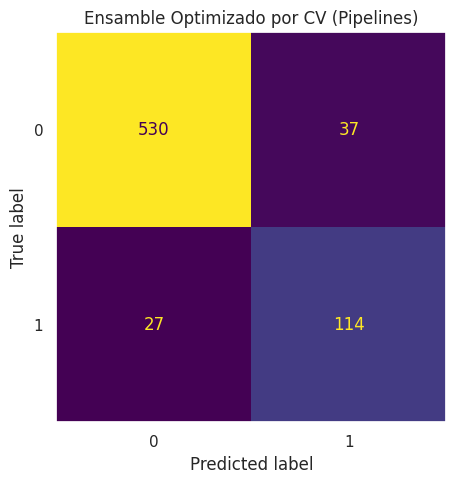

In [52]:
n_folds = 10
skf = StratifiedKFold(n_splits=n_folds, shuffle=True, random_state=seed)

# Arrays para guardar las predicciones "limpias" (Out-of-Fold)
# Inicializamos con ceros del tamaño del TRAIN
oof_probs_grid = np.zeros(len(y_train))
oof_probs_tree = np.zeros(len(y_train))

print(f"Generando predicciones Out-of-Fold con CV ({n_folds} folds)...")

# --- 1. BUCLE DE VALIDACIÓN CRUZADA (GENERAR OOF) ---
# Iteramos sobre los índices del Train
for fold, (train_idx, val_idx) in enumerate(skf.split(X_train, y_train)):
    
    # 1.1 Separamos datos de este Fold (usamos iloc para asegurar que pandas no falle)
    X_tr_fold = X_train.iloc[train_idx]
    y_tr_fold = y_train.iloc[train_idx]
    X_val_fold = X_train.iloc[val_idx]
    # y_val_fold no hace falta para predecir, solo X
    
    # 1.2 CLONAMOS los pipelines originales
    # Esto crea una copia "virgen" (sin entrenar) con los mismos hiperparámetros
    pipe_grid_fold = clone(modelo_elegido_logistica)
    pipe_tree_fold = clone(modelo_elegido_tree)
    
    # 1.3 Entrenamos en el 80% (X_tr_fold)
    pipe_grid_fold.fit(X_tr_fold, y_tr_fold)
    pipe_tree_fold.fit(X_tr_fold, y_tr_fold)
    
    # 1.4 Predecimos en el 20% de validación (X_val_fold)
    # Guardamos la probabilidad de la clase 1 (Churn)
    oof_probs_grid[val_idx] = pipe_grid_fold.predict_proba(X_val_fold)[:, 1]
    oof_probs_tree[val_idx] = pipe_tree_fold.predict_proba(X_val_fold)[:, 1]

print("Predicciones OOF generadas. Optimizando pesos...")

# --- 2. OPTIMIZACIÓN DE PESOS SOBRE EL TRAIN COMPLETO (USANDO OOF) ---
best_score = -1
best_config = None

# Probamos pesos del 0.0 al 1.0
for w_grid in np.linspace(0, 1, 101): 
    w_tree = 1.0 - w_grid
    
    # Combinamos las probabilidades OOF (que simulan datos nunca vistos)
    probs_ens_oof = (w_grid * oof_probs_grid) + (w_tree * oof_probs_tree)
    
    # Probamos thresholds
    for thr in np.linspace(0.2, 0.8, 61):
        y_pred_oof = (probs_ens_oof >= thr).astype(int)
        
        # Optimizamos por F1-Score (el equilibrio más honesto)
        score = f1_score(y_train, y_pred_oof)
        
        if score > best_score:
            best_score = score
            best_config = {"w_grid": w_grid, "w_tree": w_tree, "thr": thr, "f1_oof": score}

print(f"\n¡Configuración Óptima Encontrada (Validación Robusta)!")
print(f"Peso Pipeline 1 (Grid/Logística): {best_config['w_grid']:.2f}")
print(f"Peso Pipeline 2 (Tree/Árbol):     {best_config['w_tree']:.2f}")
print(f"Threshold óptimo:                 {best_config['thr']:.2f}")



probs_grid_test = modelo_elegido_logistica.predict_proba(X_test)[:, 1]
probs_tree_test = modelo_elegido_tree.predict_proba(X_test)[:, 1]

# Aplicamos la fórmula ganadora
probs_ens_test = (best_config["w_grid"] * probs_grid_test) + (best_config["w_tree"] * probs_tree_test)
y_pred_test = (probs_ens_test >= best_config["thr"]).astype(int)

# Métricas Finales
print("\n=== RESULTADOS FINALES EN TEST ===")
print(f"Accuracy:  {accuracy_score(y_test, y_pred_test):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred_test):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_test):.4f}")
print(f"F1 Score:  {f1_score(y_test, y_pred_test):.4f}")



# Matriz
cm = confusion_matrix(y_test, y_pred_test, labels=[0, 1])

# Plot con mismo formato
fig, ax = plt.subplots(figsize=(6, 5))

ConfusionMatrixDisplay(cm, display_labels=[0, 1]).plot(
    values_format="d",
    ax=ax,
    colorbar=False
)

ax.set_title("Ensamble Optimizado por CV (Pipelines)")
ax.grid(False)

plt.tight_layout()
plt.savefig('confusion_matrix_ensemble_final.svg')
plt.show()